# LoRa como Frequency Shift Chirp Modulation (FSCM) — V8
**Universidad Nacional de Córdoba · FCEFyN · Procesamiento de Señales**
**Docentes:** Martín Ayarde (práctico), Graciela Corral Briones (teórico)
**Integrante:** Emanuel Pinque

**Objetivo:** modular y demodular LoRa con SF configurable y **detectar el preámbulo** (está o no está, y dónde empieza), en simulación y con el ADALM-Pluto.

**Métricas**
| Métrica | Qué cuenta |
|---|---|
| **BER** (*Bit Error Rate*) | bits errados / bits enviados |
| **SER** (*Symbol Error Rate*) | símbolos errados / símbolos enviados |
| **FER** (*Frame Error Rate*) | tramas con el **preámbulo no detectado** / tramas enviadas |

**Organización**
- **Parte 1 — Simulación:** funciones base, modulación/demodulación, BER y SER (Fig. 1 de Vangelista), detección del preámbulo por fases y FER.
- **Parte 2 — SDR:** detección del preámbulo por fases con el Pluto (trama con silencio) y FER, SER y BER vs `tx_gain`.
- **Parte 3 — Opcional:** decodificación del payload paso a paso, LMMSE, falsas alarmas y ROC, y test real del Pluto con `fixPreamble`.

> Las celdas del Pluto necesitan el equipo conectado.

# Parte 1 — SIMULACIÓN

## 1. Funciones base
- **symbolChirp:** chirp de un símbolo, ecs. (2)–(3) del paper: $c[k]=\frac{1}{\sqrt{N}}e^{j2\pi[(s+k)\bmod N]k/N}$, con $N=2^{SF}$. Con `up=False` da el downchirp.
- **Chirp:** concatena los chirps de una lista de símbolos y le puede sumar ruido.
- **makePreamble:** 8 upchirps + 2 downchirps + ¼ de downchirp (10.25 símbolos).
- **sendPayload:** trama = preámbulo + payload.
- **symbolToBits / bitErrors:** ec. (1), $s=\sum w_h 2^h$ con $w_0$ el LSB. Solo se usan para contar bits (BER).
- **snrToSigma:** SNR por muestra (dB) → desvío del ruido por componente. El chirp tiene potencia $1/N$ por muestra: $\sigma=\sqrt{\frac{1}{2N\,10^{SNR/10}}}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from numbers import Real

##estilo comun de todas las graficas
plt.rcParams.update({"figure.dpi":110,"axes.grid":True,"grid.linestyle":"--","grid.alpha":0.4,
                     "axes.titlesize":12,"axes.labelsize":10,"legend.fontsize":9,"lines.linewidth":1.5})

##chirp de un simbolo, dividido sqrt(N) para que tenga energia 1
def symbolChirp(SF:int, symbol:int, up: bool):
    N = 2**SF
    sgn = 1 if up else -1
    time = np.arange(0, N, 1)
    phase = 2 * np.pi * ((symbol + time) % N) * time / N
    return np.exp(1j * sgn * phase) / np.sqrt(N)

class Chirp:
    def __init__(self, SF:int, symbols: list[int], up: bool):
        self.f=[]
        for symbol in symbols:
            c = symbolChirp(SF,symbol,up)
            self.f = np.concatenate((self.f,c))
    def getSamples(self):
        return self.f
    ##ruido blanco gaussiano complejo, sigma por componente
    def addNoise(self, sigma):
        n = len(self.f)
        noise = np.random.normal(0, sigma, n) + 1j * np.random.normal(0, sigma, n)
        self.f = self.f + noise

##8 upchirps + 2 downchirps + 1/4 de downchirp
def makePreamble(SF:int,noise:float):
    upChirps = Chirp(SF,[0]*8,True)
    upChirps.addNoise(noise)
    downChirps = Chirp(SF,[0]*2,False)
    downChirps.addNoise(noise)
    downChirp = Chirp(SF,[0],False)
    downChirp.addNoise(noise)
    n = len(downChirp.f)
    indx = int((n*3)/4)
    downChirp.f = downChirp.f[:-indx]
    return np.concatenate((upChirps.f,downChirps.f,downChirp.f))

##trama = preambulo + payload (lista de simbolos)
def sendPayload(SF:int,pl:list[int],noise):
    p = makePreamble(SF,noise)
    pl = Chirp(SF,pl,True)
    pl.addNoise(noise)
    return np.concatenate((p,pl.f))

##simbolo -> SF bits (LSB primero), para contar bits errados
def symbolToBits(s:int, SF:int):
    return [(int(s) >> h) & 1 for h in range(SF)]

##bits distintos entre dos simbolos
def bitErrors(tx:int, est:int, SF:int):
    bitsTx = symbolToBits(tx,SF)
    bitsEst = symbolToBits(est,SF)
    errors = 0
    for i in range(SF):
        if bitsTx[i] != bitsEst[i]:
            errors = errors + 1
    return errors

##snr = 10 log(ps/pn), ps = 1/2^SF por muestra -> pn = 1/(10^(snr/10) 2^SF), sigma = sqrt(pn/2)
def snrToSigma(snr, SF:int):
    pn = 1/(10**(snr/10)*(2**SF))
    return np.sqrt(pn/2)

## 1b. Clase `Sampling` (receptor)
Guarda las muestras (simuladas o del Pluto) y hace todo lo del receptor:
- **chirpDown / estimateSymbol:** receptor óptimo del paper (ecs. 10–16). Multiplicar por el downchirp $e^{-j2\pi k^2/N}$ deja un tono puro y la FFT lo concentra en el bin del símbolo. El símbolo estimado es el bin de mayor módulo.
- **freqSelective:** canal selectivo del paper, $h=[\sqrt{0.8},\sqrt{0.2}]$.
- **identifyPreamble:** coeficiente de correlación cruzada normalizado entre la captura $x$ y el preámbulo $p$, vistos como dos procesos aleatorios: $\hat\rho_\ell=\dfrac{\sum_n x[n+\ell]\,p^*[n]}{\sqrt{\sum_n|x[n]|^2\,\sum_n|p[n]|^2}}$, con $|\hat\rho_\ell|\le 1$. Hay preámbulo si $\max_\ell|\hat\rho_\ell|$ supera el umbral. Devuelve el índice de `np.correlate` donde **termina** el preámbulo (desarrollo en la Fase 3 de la sección 5).
- **fixPreamble / decodeSymbols / isCorrectPayload:** realinean la captura y decodifican el payload (se usan en la parte opcional y en el Pluto).
- **graph...:** frecuencia instantánea, FFT, fase y parte real.

In [ ]:
class Sampling:
    def __init__(self,array:np.ndarray):
        self.lenght = len(array)
        self.samples = array

    ##Metodo dechirp el utilizado por vangelista utiliza el producto punto entre funciones
    ##en el paper lo optimiza usando una fft este sera de utilidad para hallar el simbolo enviado
    def chirpDown(self):
        time = np.arange(0,self.lenght,1)
        d = self.samples * np.exp(-2j * np.pi * (time ** 2) / self.lenght)
        return np.fft.fft(d) / np.sqrt(self.lenght)

    ##simplemente retorna el argumento maximo de la fft
    def estimateSymbol(self):
        fft = self.chirpDown()
        return int(np.argmax(np.abs(fft)))
    def isCorrectSymbol(self,symbol:int):
        return self.estimateSymbol() == symbol

    ##canal selectivo del paper (2 taps, energia 1), recortado al largo original
    def freqSelective(self, h=np.array([np.sqrt(0.8),np.sqrt(0.2)])):
        self.samples = np.convolve(self.samples,h)[:self.lenght]

    ##coeficiente de correlacion rho_l = R_xp[l] / sqrt(R_xx[0] R_pp[0]) = sum x[n+l] p*[n] / (||x|| ||p||), |rho_l| va de 0 a 1
    ##lag = indice de la correlacion "full" donde TERMINA el preambulo
    def identifyPreamble(self,preamble:np.ndarray,threshold:float):
        rho = np.correlate(self.samples,preamble,mode="full")/(np.linalg.norm(preamble)*np.linalg.norm(self.samples))
        lag = np.argmax(np.abs(rho))
        if(np.abs(rho[lag])>threshold):
            return True,lag
        else:
            return False,math.nan
    ##OPCIONAL PARA LA DECODIFICACION
    ##rota la señal para que el preambulo quede al inicio (empieza en lag - len(preamble) + 1)
    def fixPreamble(self,preamble:np.ndarray,threshold:float):
        (correct,lag) = self.identifyPreamble(preamble,threshold)
        if(correct):
            self.samples = np.roll(self.samples,-1-lag+len(preamble))
            return True
        else:
            return False
    ##OPCIONAL PARA LA DECODIFICACION
    ##saca el preambulo y estima un simbolo por ventana de 2^SF muestras. nan si no hay preambulo
    def decodeSymbols(self,preamble:np.ndarray,threshold,done=False):
        SF = round(np.log2(len(preamble)/10.25))
        if(not done):
            FoundPreamble = self.fixPreamble(preamble,threshold)
        else:
            FoundPreamble=True
        if(not FoundPreamble):
            return math.nan
        payload = self.samples[len(preamble):]
        nSymbols = int(len(payload)/(2**SF))
        symbols = [0]*nSymbols
        start = 0
        end = 2**SF
        for i in range(nSymbols):
            window = Sampling(payload[start:end])
            symbols[i] = window.estimateSymbol()
            start += 2**SF
            end += 2**SF
        return symbols
    ##OPCIONAL saca el payload error rate
    def isCorrectPayload(self,expectedPayload,preamble,threshold,done=False):
        p = self.decodeSymbols(preamble,threshold,done)
        if isinstance(p, Real) and math.isnan(p):
            return math.nan
        else:
            return p == expectedPayload

    ##---------------- Graficos ----------------
    def graphReal(self, title="Parte real de la señal"):
        plt.figure(figsize=(8,4))
        plt.plot(np.arange(0,self.lenght,1),self.samples.real,linewidth=1.2)
        plt.xlabel("Muestra k"); plt.ylabel("Re{x[k]}"); plt.title(title)
        plt.tight_layout(); plt.show()

    def graphPhase(self, title="Fase desenrollada de la señal"):
        plt.figure(figsize=(8,4))
        plt.plot(np.arange(0,self.lenght,1),np.unwrap(np.angle(self.samples)),linewidth=1.2)
        plt.xlabel("Muestra k"); plt.ylabel("Fase (rad)"); plt.title(title)
        plt.tight_layout(); plt.show()

    ##frecuencia instantanea = diferencia de la fase desenrollada
    ##marks = zonas a sombrear (frameMarks), ax = eje donde dibujar (None crea una figura)
    def graphFrecuency(self, title="Frecuencia instantánea", marks=None, ax=None):
        frec = np.diff(np.unwrap(np.angle(self.samples)))
        own = ax is None
        if own:
            plt.figure(figsize=(9,4.2))
            ax = plt.gca()
        ax.plot(np.arange(len(frec)),frec,linewidth=1.1,color="tab:blue")
        if marks is not None:
            for i in range(len(marks)):
                x0 = marks[i][0]      ##inicio de la zona
                x1 = marks[i][1]      ##fin de la zona
                label = marks[i][2]   ##texto
                color = marks[i][3]
                ax.axvspan(x0,x1,color=color,alpha=0.15)
                ax.text((x0+x1)/2,0.97,label,transform=ax.get_xaxis_transform(),ha="center",va="top",fontsize=8)
        ax.set_xlabel("Muestra k"); ax.set_ylabel("Frecuencia (rad/muestra)"); ax.set_title(title)
        if own:
            plt.tight_layout(); plt.show()

    ##|fft| tras el dechirp, sent = simbolo enviado para marcarlo
    def graphFFT(self, title="FFT tras dechirp", sent=None):
        mag = abs(self.chirpDown())
        peak = int(np.argmax(mag))
        plt.figure(figsize=(8,4))
        plt.plot(np.arange(len(mag)),mag,marker="o",markersize=3,linewidth=1.2,label="|FFT|")
        plt.plot(peak,mag[peak],"rv",markersize=9,label="Símbolo estimado = %d"%peak)
        if sent is not None:
            plt.axvline(sent,color="tab:green",linestyle=":",linewidth=1.5,label="Símbolo enviado = %d"%sent)
        plt.xlabel("Bin de frecuencia (símbolo)"); plt.ylabel("|FFT| normalizada"); plt.title(title)
        plt.legend(); plt.tight_layout(); plt.show()

##zonas de una trama para sombrear: preambulo y un tramo por simbolo del payload. shift = donde empieza
def frameMarks(SF, nSym, shift=0):
    N = 2**SF
    marks = [(shift,shift+8*N,"8 upchirps","tab:green"),
             (shift+8*N,shift+10*N,"2 downchirps","tab:red"),
             (shift+10*N,shift+int(10.25*N),"¼","tab:orange")]
    for i in range(nSym):
        x0 = shift+int(10.25*N)+i*N
        marks.append((x0,x0+N,"s%d"%(i+1),"tab:blue" if i%2==0 else "tab:gray"))
    return marks

## 1c. Modular y demodular un símbolo (sin ruido)
- **Arriba:** frecuencia instantánea de dos símbolos con SF = 8. Es una rampa y el símbolo corre dónde arranca: el 64 empieza a un cuarto del recorrido y al llegar al máximo vuelve a 0.
- **Abajo:** salida del demodulador. Tras el dechirp queda un tono puro y la FFT da **un único pico** en el símbolo enviado.

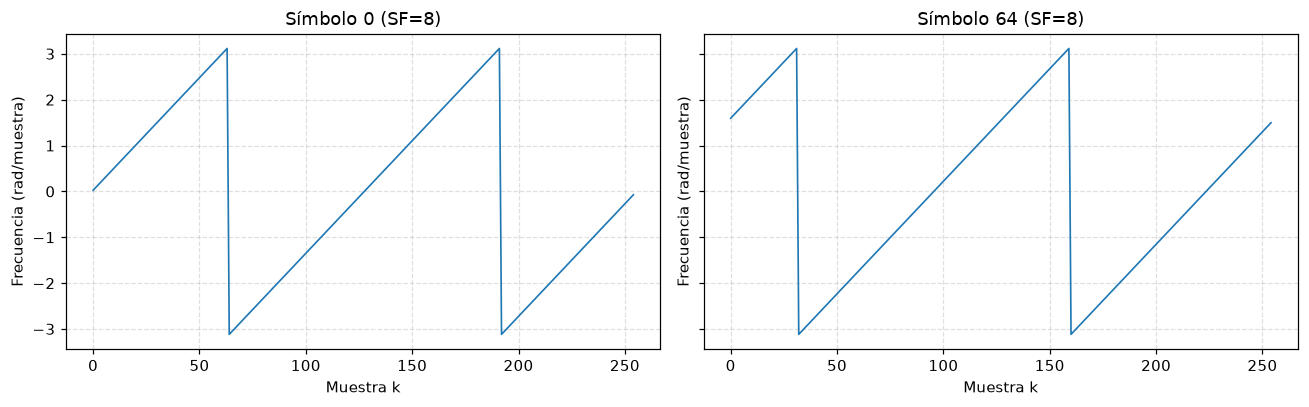

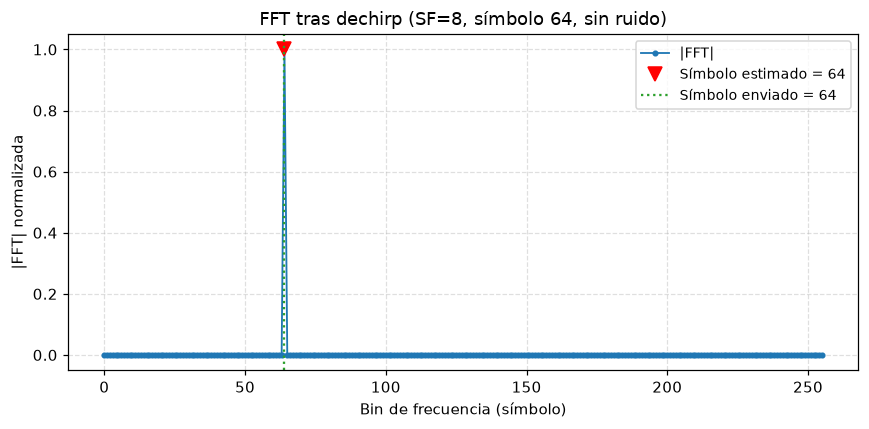

símbolo enviado: 64 | estimado: 64


In [3]:
fig,ax = plt.subplots(1,2,figsize=(12,3.8),sharey=True)
simbolos = [0,64]
##equivale a: for (int k = 0; k < simbolos.length; k++)
for k in range(len(simbolos)):
    s = simbolos[k]
    Sampling(Chirp(8,[s],True).getSamples()).graphFrecuency(title="Símbolo %d (SF=8)"%s,ax=ax[k])
plt.tight_layout()
plt.show()

c = Sampling(Chirp(8,[64],True).getSamples())
c.graphFFT(title="FFT tras dechirp (SF=8, símbolo 64, sin ruido)",sent=64)
print("símbolo enviado: 64 | estimado:",c.estimateSymbol())

## 1d. El mismo símbolo con ruido
Con ruido el chirp casi no se ve en el tiempo, pero el pico de la FFT sigue sobresaliendo: el dechirp + FFT junta en un bin la energía de las $N$ muestras (**ganancia de procesamiento** $N$, 24 dB con SF = 8). Por eso LoRa funciona con SNR negativa.

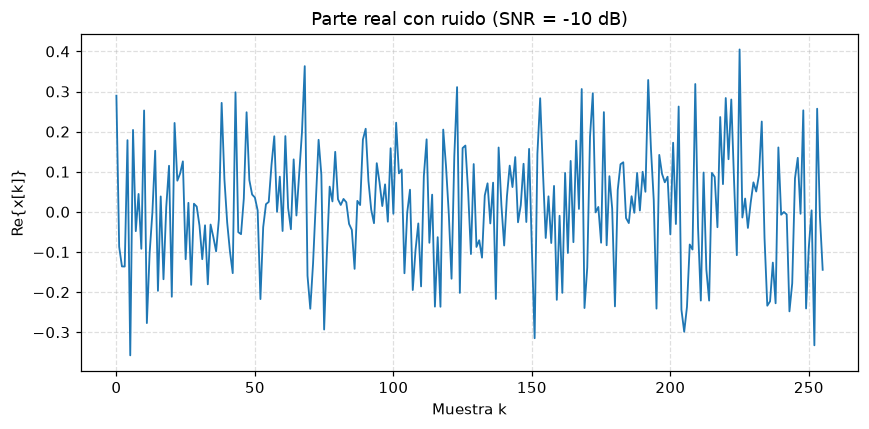

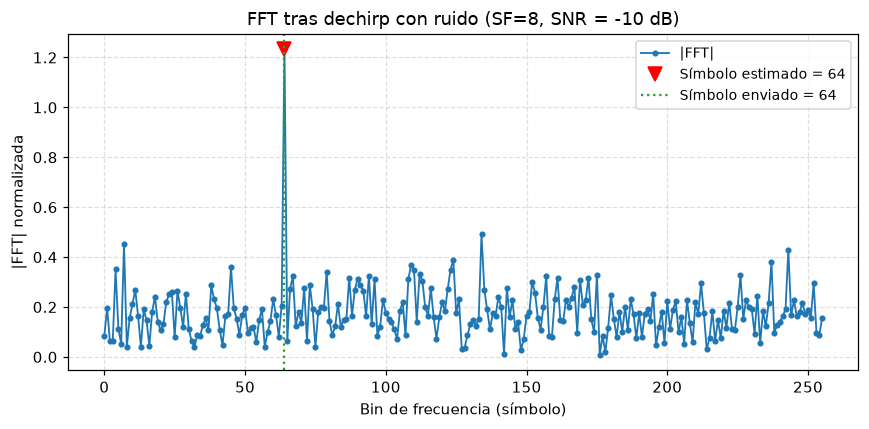

símbolo enviado: 64 | estimado: 64


In [4]:
SF = 8
snr = -10   ##dB por muestra
np.random.seed(1)
c = Chirp(SF,[64],True)
c.addNoise(snrToSigma(snr,SF))
c = Sampling(c.getSamples())
c.graphReal(title="Parte real con ruido (SNR = %d dB)"%snr)
c.graphFFT(title="FFT tras dechirp con ruido (SF=8, SNR = %d dB)"%snr,sent=64)
print("símbolo enviado: 64 | estimado:",c.estimateSymbol())

## 1e. Secuencia de chirps y espectrograma
Cada símbolo ocupa $2^{SF}$ muestras. El espectrograma muestra lo mismo que la frecuencia instantánea y es lo que se usa con el Pluto.

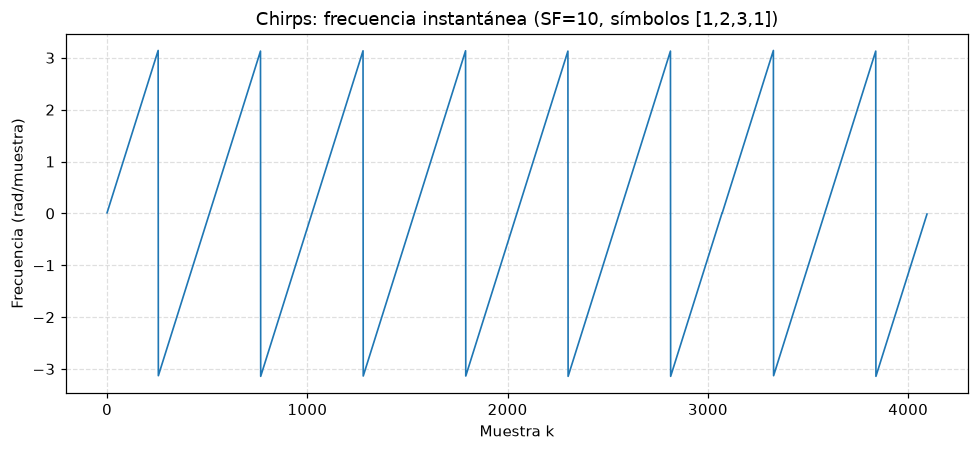

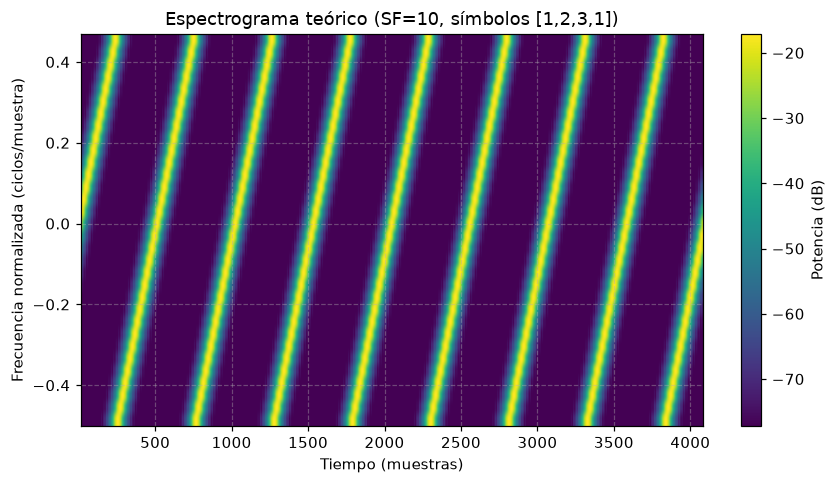

In [5]:
##espectrograma: NFFT=32 de ventana y noverlap=31. Fs=1 -> frecuencia normalizada, Fs=bw -> Hz
def graphSpectrogram(samples,Fs,title):
    plt.figure(figsize=(8,4.5))
    _,_,_,im = plt.specgram(samples,NFFT=32,noverlap=31,Fs=Fs,cmap="viridis")
    ##60 dB bajo el maximo para que el piso de ruido no tape el chirp
    im.set_clim(im.get_array().max()-60,im.get_array().max())
    if Fs == 1:
        plt.xlabel("Tiempo (muestras)"); plt.ylabel("Frecuencia normalizada (ciclos/muestra)")
    else:
        plt.xlabel("Tiempo (s)"); plt.ylabel("Frecuencia relativa al LO (Hz)")
    plt.title(title)
    plt.colorbar(label="Potencia (dB)")
    plt.tight_layout()
    plt.show()

c = Sampling(Chirp(10,[1,2,3,1],True).f)
c.graphFrecuency(title="Chirps: frecuencia instantánea (SF=10, símbolos [1,2,3,1])")
graphSpectrogram(c.samples,1,"Espectrograma teórico (SF=10, símbolos [1,2,3,1])")

## 2. BER y SER símbolo a símbolo: canal plano y selectivo
- **Canal plano:** solo ruido.
- **Canal selectivo:** $h=[\sqrt{0.8},\sqrt{0.2}]$ (`freqSelective`), antes del ruido.
- **SER** = símbolos errados / símbolos enviados.
- **BER** = bits errados / bits enviados. Un símbolo errado cambia entre 1 y SF bits.

En escala log los puntos con 0 errores no se dibujan: la curva se corta ahí.

In [6]:
##un intento: simbolo (fijo o aleatorio si send=None) -> chirp -> (canal selectivo) -> ruido -> receptor
def sendOneSymbol(SF,send,noise,sel=False):
    tx = np.random.randint(0,2**SF) if send is None else send
    c = Chirp(SF,[tx],True)
    if sel:
        s = Sampling(c.f)
        s.freqSelective()
        c.f = s.samples
    c.addNoise(noise)
    return tx, Sampling(c.f).estimateSymbol()

def getSER(N,SF,send,noise,sel=False):
    errors = 0
    for i in range(N):
        (tx,est) = sendOneSymbol(SF,send,noise,sel)
        if tx != est:
            errors = errors +1
    return errors/N

def getBER(N,SF,send,noise,sel=False):
    errors = 0
    for i in range(N):
        (tx,est) = sendOneSymbol(SF,send,noise,sel)
        errors += bitErrors(tx,est,SF)
    return errors/(N*SF)

##curva de error vs SNR: canal plano contra selectivo
def graphRateVsSNR(name,getRate,N,SF,send,snrs):
    flat = np.zeros(len(snrs))
    sel = np.zeros(len(snrs))
    for indx in range(len(snrs)):
        noise = snrToSigma(snrs[indx],SF)
        flat[indx] = getRate(N,SF,send,noise)          ##canal plano
        sel[indx] = getRate(N,SF,send,noise,True)      ##canal selectivo
    plt.figure(figsize=(8,5.5))
    plt.semilogy(snrs,flat,marker="s",label="Flat FSCM")
    plt.semilogy(snrs,sel,marker="d",label="Freq.sel. FSCM")
    plt.xlabel("SNR (dB por muestra)")
    plt.ylabel(name)
    plt.title("%s vs SNR (SF=%d)"%(name,SF))
    plt.legend()
    plt.tight_layout()
    plt.show()

print("SER:",getSER(100,8,2,0.3),"BER:",getBER(100,8,2,0.3))

SER: 0.42 BER: 0.2175


## 3. Validación: Fig. 1 de Vangelista (2017)
Mismos parámetros que la Fig. 1 del paper: SF = 7, SNR de −12 a −1 dB, símbolo aleatorio, 1000 símbolos por punto (7000 bits). El canal selectivo queda un poco peor: la copia retrasada le quita energía al pico, pero como cada chirp barre toda la banda la pérdida es chica.

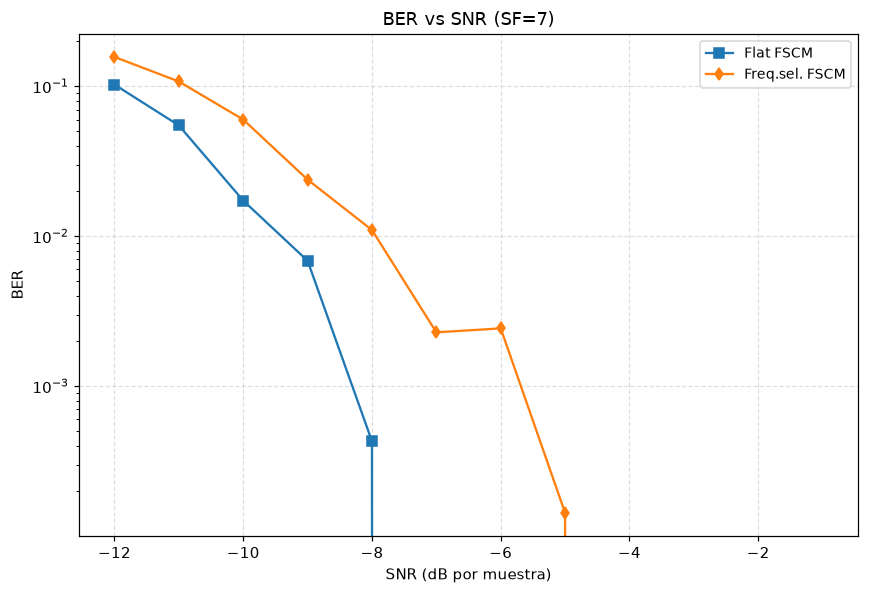

In [7]:
np.random.seed(0)
graphRateVsSNR("BER",getBER,1000,7,None,np.arange(-12,0,1))

### 3b. BER y SER con SF = 4 (rango amplio de SNR)

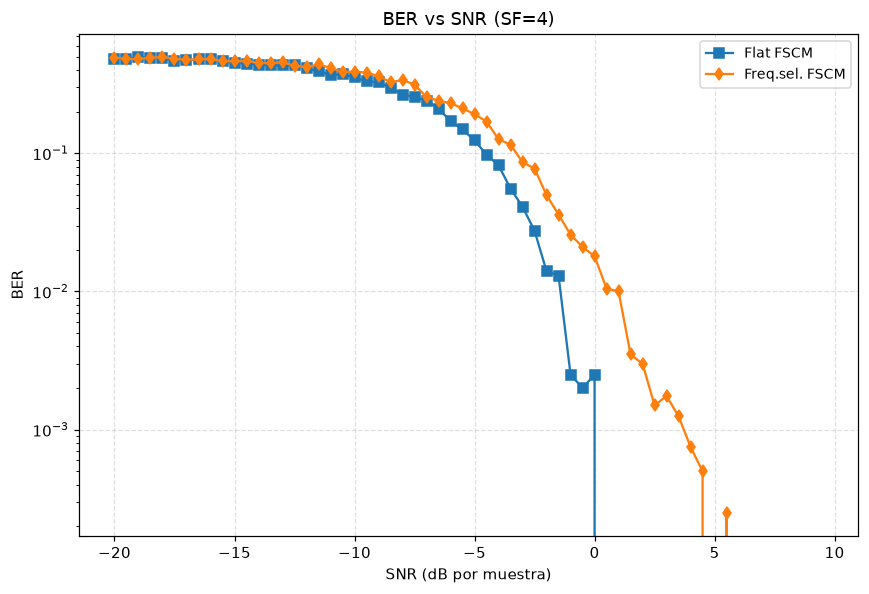

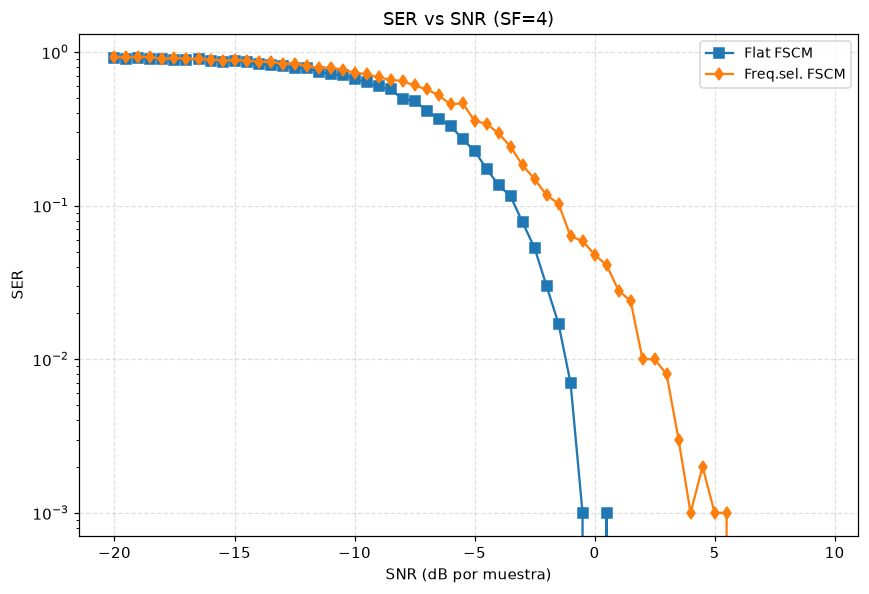

In [8]:
np.random.seed(0)
snrs = np.arange(-20,10,0.5)
graphRateVsSNR("BER",getBER,1000,4,2,snrs)
graphRateVsSNR("SER",getSER,1000,4,2,snrs)

## 4. Preámbulo
Del práctico (no está en el paper): 8 upchirps de símbolo 0 para detectar, 2 downchirps y ¼ de downchirp que marcan dónde termina. Son $10.25\cdot2^{SF}$ muestras con energía $E_p=10.25$. El receptor lo conoce: es la referencia con la que se busca la trama.

muestras del preámbulo: 2624


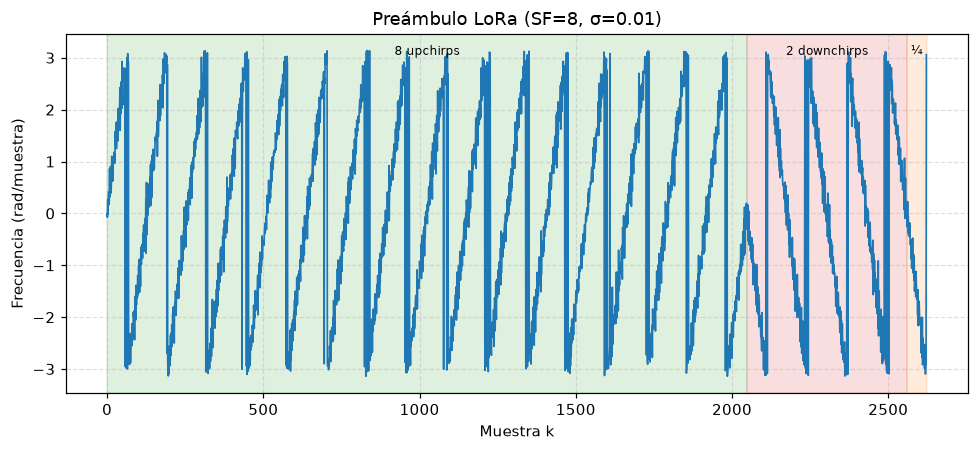

In [9]:
c = Sampling(makePreamble(8,0.01))
print("muestras del preámbulo:",len(c.samples))
c.graphFrecuency(title="Preámbulo LoRa (SF=8, σ=0.01)",marks=frameMarks(8,0))

## 5. Detección del preámbulo por fases
El paper supone sincronismo perfecto; en una captura real no se sabe cuándo llega la trama. Se simula una captura con **silencio** (`np.zeros`) antes y después de la trama y ruido en toda la captura. El silencio de antes (`before`) es el retardo que el detector tiene que encontrar.

| Fase | Qué se hace |
|---|---|
| 1 | Captura: silencio + preámbulo + payload + silencio, con ruido |
| 2 | Correlación cruzada estimada con el preámbulo: $\hat R_{xp}[\ell]=\frac{1}{L}\sum_n x[n+\ell]\,p^*[n]$ (un valor por retardo $\ell$) |
| 3 | Normalización: $\hat\rho_\ell=\dfrac{\hat R_{xp}[\ell]}{\sqrt{\hat R_{xx}[0]\,\hat R_{pp}[0]}}$, con $\lvert\hat\rho_\ell\rvert\in[0,1]$ |
| 4 | Decisión: hay preámbulo si $\max_\ell\lvert\hat\rho_\ell\rvert>$ umbral |
| 5 | Ubicación: $\hat\ell_0=\arg\max_\ell\lvert\hat\rho_\ell\rvert$ es donde **termina** el preámbulo; el inicio es `lag - len(preamble) + 1` |

$\hat\rho$ no depende de la escala de la señal (por eso sirve en el Pluto), pero sí de todo lo que hay en la captura además del preámbulo: payload, ruido y silencio con ruido agrandan $\hat R_{xx}[0]$ y bajan $\lvert\hat\rho\rvert$.

In [10]:
##silencio: ceros antes y despues de la señal
def addSilence(samples, before=0, after=0):
    return np.concatenate((np.zeros(int(before)), samples, np.zeros(int(after))))

##ruido blanco gaussiano complejo sobre cualquier arreglo, sigma por componente
def addNoise(samples, sigma):
    n = len(samples)
    return samples + np.random.normal(0,sigma,n) + 1j*np.random.normal(0,sigma,n)

### Fase 1 — Captura con silencio y ruido

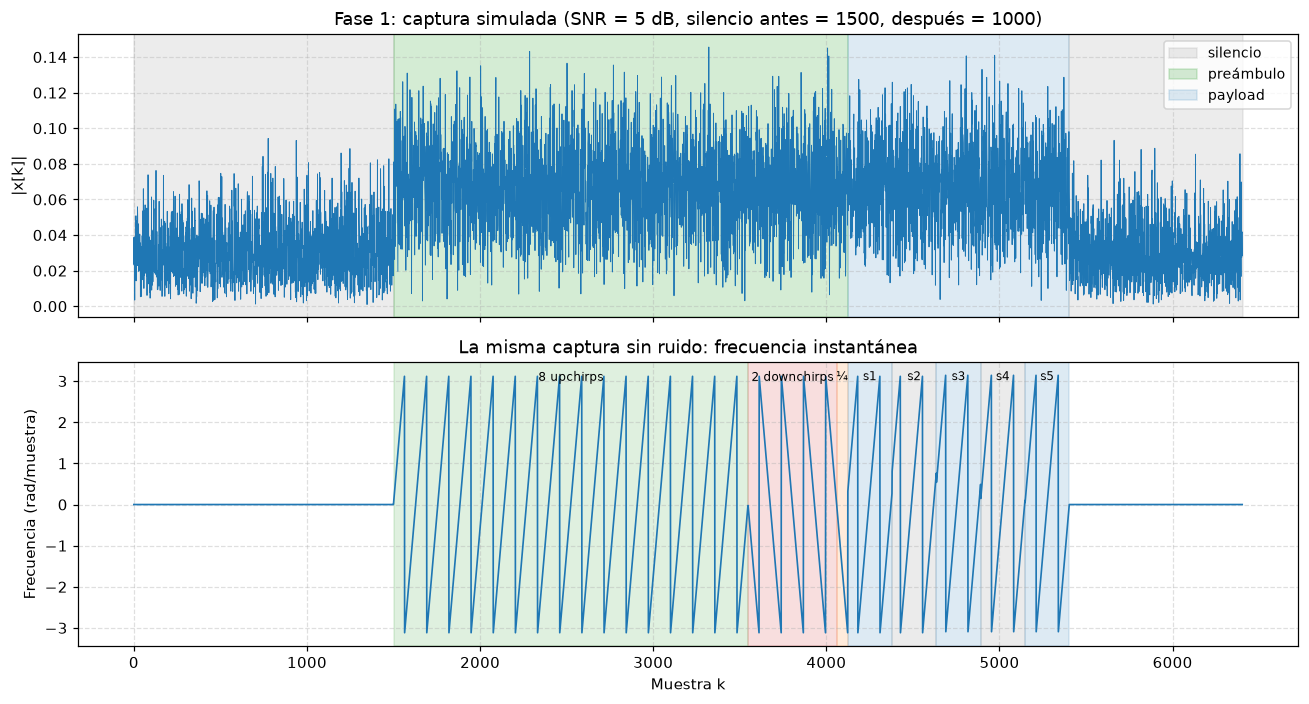

In [11]:
np.random.seed(7)
SF = 8
PL = [12,32,21,5,1]
snr = 5          ##dB por muestra
before = 1500    ##silencio antes = retardo a encontrar
after = 1000     ##silencio despues
threshold = 0.5

N = 2**SF
preamble = makePreamble(SF,0.0)                       ##referencia sin ruido
trama = sendPayload(SF,PL,0.0)
x = addNoise(addSilence(trama,before,after),snrToSigma(snr,SF))

fig,ax = plt.subplots(2,1,figsize=(12,6.5),sharex=True)
ax[0].plot(np.abs(x),linewidth=0.6)
ax[0].axvspan(0,before,color="gray",alpha=0.15,label="silencio")
ax[0].axvspan(before,before+len(preamble),color="tab:green",alpha=0.2,label="preámbulo")
ax[0].axvspan(before+len(preamble),before+len(trama),color="tab:blue",alpha=0.15,label="payload")
ax[0].axvspan(before+len(trama),len(x),color="gray",alpha=0.15)
ax[0].set_ylabel("|x[k]|")
ax[0].set_title("Fase 1: captura simulada (SNR = %d dB, silencio antes = %d, después = %d)"%(snr,before,after))
ax[0].legend(loc="upper right")
Sampling(addSilence(trama,before,after)).graphFrecuency(title="La misma captura sin ruido: frecuencia instantánea",marks=frameMarks(SF,len(PL),before),ax=ax[1])
plt.tight_layout()
plt.show()

### Fase 2 — Correlación con el preámbulo
`np.correlate(x, p, "full")` calcula $\sum_n x[n+\ell]\,p^*[n]$ para cada retardo $\ell$, es decir $L\cdot\hat R_{xp}[\ell]$: la correlación cruzada estimada sin el factor $1/L$ (que se cancela al normalizar). El pico aparece cuando quedan alineados; los picos laterales cada $2^{SF}$ muestras son los upchirps del preámbulo alineándose con upchirps corridos. Sin ruido el pico vale $E_p=\sum_n|p[n]|^2=10.25$.

La figura muestra las dos entradas de la correlación (el preámbulo teórico $p[n]$ y la captura $x[n]$) y el resultado $|c[\ell]|$.

In [ ]:
c = np.abs(np.correlate(x,preamble,mode="full"))
Ep = np.sum(np.abs(preamble)**2)
lag = int(np.argmax(c))

fig,ax = plt.subplots(3,1,figsize=(12,10))
##las dos entradas de la correlacion: el preambulo teorico y la captura
Sampling(preamble).graphFrecuency(title="Preámbulo teórico p[n]: la referencia contra la que se correlaciona",marks=frameMarks(SF,0),ax=ax[0])
Sampling(x).graphFrecuency(title="Captura x[n]: silencio + trama + silencio (SNR = %d dB)"%snr,marks=frameMarks(SF,len(PL),before),ax=ax[1])
ax[1].set_xlim(0,len(x))
##el resultado: un valor por cada retardo
ax[2].plot(c,linewidth=0.8)
ax[2].plot(lag,c[lag],"rv",markersize=9,label="máximo = %.2f en el índice %d"%(c[lag],lag))
ax[2].axhline(Ep,color="tab:green",linestyle="--",linewidth=1,label="E$_p$ = %.2f"%Ep)
ax[2].set_xlabel("Índice de la correlación ℓ (muestra donde termina el preámbulo)")
ax[2].set_ylabel("|c|")
ax[2].set_title("Fase 2: correlación cruzada |Σ x[n+ℓ] p*[n]|")
ax[2].legend(loc="upper right")
plt.tight_layout()
plt.show()

### Fase 3 — Normalización ($\hat\rho$): correlación entre dos procesos aleatorios

**1. El modelo.** La captura $x[n]$ y el preámbulo $p[n]$ se tratan como dos procesos aleatorios. La captura es el preámbulo corrido $\ell_0$ muestras, afectado por el canal, más ruido:
$$x[n]=\alpha\,p[n-\ell_0]+w[n]$$
donde $w[n]$ es ruido de media nula, $\alpha$ la ganancia y fase del canal y $\ell_0$ el retardo buscado.

**2. La correlación cruzada.** Mide el parecido entre $x$ y $p$ corrido $\ell$ muestras:
$$R_{xp}[\ell]=E\big[\,x[n+\ell]\;p^*[n]\,\big]$$
Como no se conoce la distribución de los procesos, la esperanza se estima con el promedio temporal de la captura:
$$\hat R_{xp}[\ell]=\frac{1}{L}\sum_n x[n+\ell]\,p^*[n]$$

**3. El coeficiente de correlación para cada retardo.** Para cada retardo $\ell$ se toman dos variables aleatorias: $X_\ell=x[n+\ell]$ (la captura corrida $\ell$ muestras) y $P=p[n]$ (el preámbulo). Su coeficiente de correlación es la covarianza dividida por el producto de las desviaciones estándar:
$$\rho_\ell=\frac{\operatorname{Cov}(X_\ell,P)}{\sigma_X\,\sigma_P}$$
Las dos variables tienen media nula (el ruido por hipótesis y el chirp porque su fase gira todo el círculo), así que la covarianza y las varianzas son correlaciones:
$$\operatorname{Cov}(X_\ell,P)=E\big[X_\ell\,P^*\big]=R_{xp}[\ell],\qquad \sigma_X^2=E\big[|X_\ell|^2\big]=R_{xx}[0],\qquad \sigma_P^2=E\big[|P|^2\big]=R_{pp}[0]$$
Las desviaciones estándar son $\sigma_X=\sqrt{R_{xx}[0]}$ y $\sigma_P=\sqrt{R_{pp}[0]}$, y el coeficiente queda:
$$\rho_\ell=\frac{R_{xp}[\ell]}{\sqrt{R_{xx}[0]\,R_{pp}[0]}}$$
Reemplazando cada esperanza por su promedio temporal, con $\hat R_{xx}[0]=\frac{1}{L}\sum_n|x[n]|^2$ y $\hat R_{pp}[0]=\frac{1}{L}\sum_n|p[n]|^2$, los $1/L$ se cancelan:
$$\hat\rho_\ell=\frac{\sum_n x[n+\ell]\,p^*[n]}{\sqrt{\sum_n|x[n]|^2\,\sum_n|p[n]|^2}}$$
- $|\hat\rho_\ell|$ va de 0 a 1, y vale 1 solo si la captura, en ese retardo, es exactamente $\alpha\,p$.
- No depende de la escala: si la señal llega más fuerte o más débil, $\hat\rho_\ell$ no cambia.

**4. Sacar el máximo.** El retardo con el mayor módulo es la posición del preámbulo:
$$\hat\ell_0=\arg\max_\ell\,|\hat\rho_\ell|$$

**¿Por qué el módulo?** Si la señal llega con la fase girada, $x[n]=e^{j\varphi}\,p[n]$, el coeficiente queda multiplicado por $e^{j\varphi}$ y su módulo no cambia, porque $|e^{j\varphi}|=1$. Por ejemplo, con $\varphi=\pi$ llega $-p[n]$ y $\hat\rho_\ell$ da negativo: en el tiempo la onda queda desfasada 180° (invertida muestra a muestra), pero la frecuencia instantánea es la misma rampa, y LoRa lleva la información solo en la frecuencia. Por eso se toma $|\hat\rho_\ell|$, que no cambia con $\varphi$.

Con el índice `"full"` de `np.correlate` el máximo marca el **final** del preámbulo; el inicio es $\hat\ell_0-\text{len}(p)+1$.

En el código, `np.correlate` da la suma del numerador, `np.linalg.norm(preamble)*np.linalg.norm(x)` da el denominador y `np.argmax(np.abs(rho))` da $\hat\ell_0$. En la captura real el payload y el ruido entran en $\hat R_{xx}[0]$, por eso el máximo queda por debajo de 1 (abajo se compara con el $\rho$ ideal sin ruido).

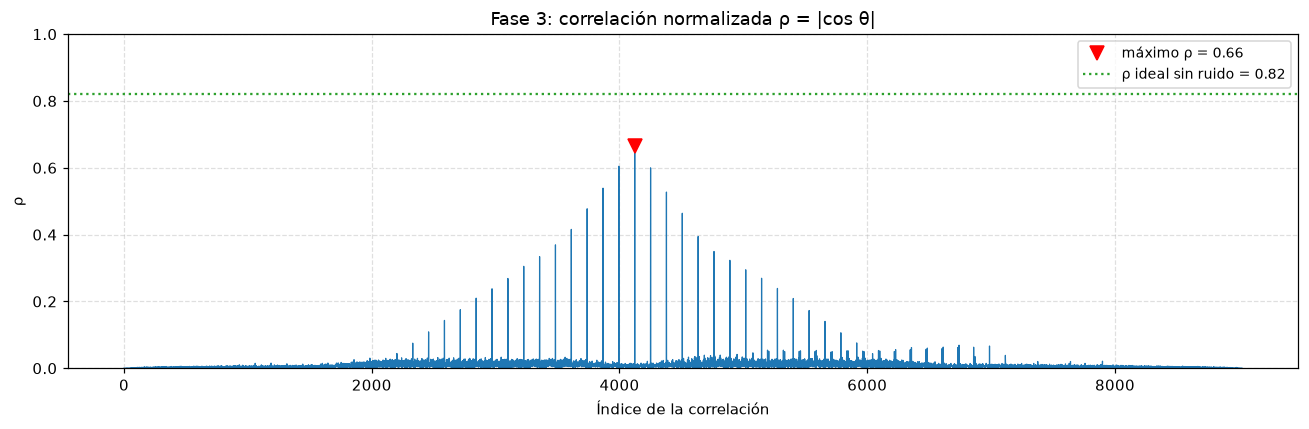

In [13]:
rho = c/(np.linalg.norm(preamble)*np.linalg.norm(x))
##rho ideal sin ruido: solo el payload y el preambulo en la captura
rhoIdeal = Ep/(np.linalg.norm(preamble)*np.linalg.norm(trama))

plt.figure(figsize=(12,4))
plt.plot(rho,linewidth=0.8)
plt.plot(lag,rho[lag],"rv",markersize=9,label="máximo ρ = %.2f"%rho[lag])
plt.axhline(rhoIdeal,color="tab:green",linestyle=":",label="ρ ideal sin ruido = %.2f"%rhoIdeal)
plt.xlabel("Índice de la correlación")
plt.ylabel("ρ")
plt.ylim(0,1)
plt.title("Fase 3: coeficiente de correlación |ρ$_ℓ$| = |R$_{xp}$[ℓ]| / (σ$_x$ σ$_p$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

### Fase 4 — Decisión con umbral

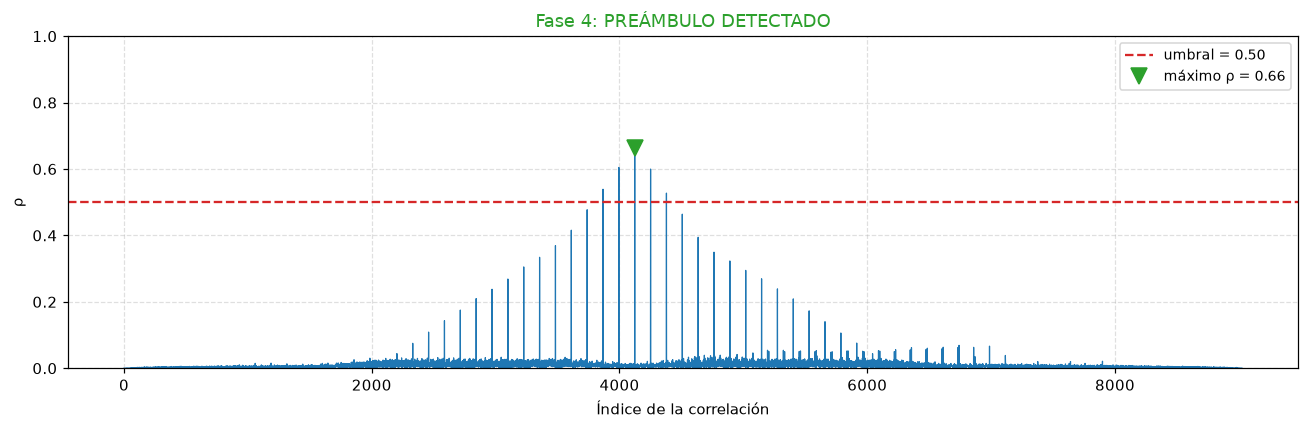

máximo ρ = 0.664, umbral = 0.50 -> detecta: True


In [14]:
detecto = rho[lag] > threshold

plt.figure(figsize=(12,4))
plt.plot(rho,linewidth=0.8)
plt.axhline(threshold,color="tab:red",linestyle="--",label="umbral = %.2f"%threshold)
plt.plot(lag,rho[lag],"v",markersize=10,color="tab:green" if detecto else "tab:red",label="máximo ρ = %.2f"%rho[lag])
plt.xlabel("Índice de la correlación")
plt.ylabel("ρ")
plt.ylim(0,1)
plt.title("Fase 4: %s"%("PREÁMBULO DETECTADO" if detecto else "NO HAY PREÁMBULO"),color="tab:green" if detecto else "tab:red")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()
print("máximo ρ = %.3f, umbral = %.2f -> detecta: %s"%(rho[lag],threshold,detecto))

### Fase 5 — Ubicación del inicio de la trama

inicio estimado = 1500 | inicio real (silencio antes) = 1500


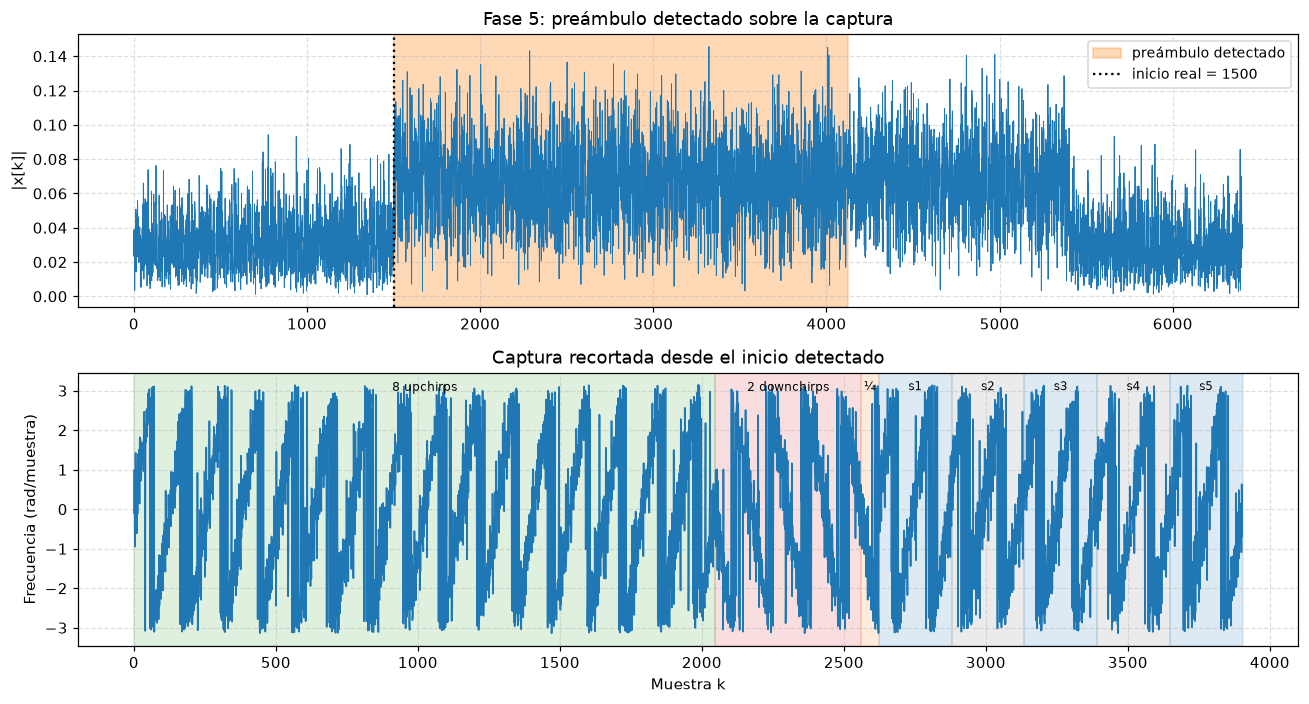

identifyPreamble: (True, np.int64(4123))


In [15]:
inicio = lag - len(preamble) + 1     ##el indice de la correlacion es donde TERMINA el preambulo
print("inicio estimado = %d | inicio real (silencio antes) = %d"%(inicio,before))

fig,ax = plt.subplots(2,1,figsize=(12,6.5))
ax[0].plot(np.abs(x),linewidth=0.6)
ax[0].axvspan(inicio,inicio+len(preamble),color="tab:orange",alpha=0.3,label="preámbulo detectado")
ax[0].axvline(before,color="k",linestyle=":",label="inicio real = %d"%before)
ax[0].set_ylabel("|x[k]|")
ax[0].set_title("Fase 5: preámbulo detectado sobre la captura")
ax[0].legend(loc="upper right")
##desde el inicio detectado la trama queda alineada: las zonas del preambulo y del payload coinciden
Sampling(x[inicio:inicio+len(trama)]).graphFrecuency(title="Captura recortada desde el inicio detectado",marks=frameMarks(SF,len(PL)),ax=ax[1])
plt.tight_layout()
plt.show()

##todo lo anterior es lo que hace identifyPreamble en una linea
print("identifyPreamble:",Sampling(x).identifyPreamble(preamble,threshold))

### 5b. Preámbulo real contra fake
Una secuencia de 8 upchirps de símbolo 0 sin los downchirps se parece al preámbulo pero no lo es. Sin ruido su $|\hat\rho_\ell|$ es $\sqrt{8/10.25}\approx0.88$, así que el umbral tiene que estar por encima para rechazarla.

La figura muestra las dos entradas de la correlación y su resultado:
- **Arriba:** el preámbulo teórico $p[n]$ (8 upchirps + 2 downchirps + ¼), la referencia que conoce el receptor. Es la misma para los dos casos.
- **Medio:** la señal que se correlaciona, $x[n]$ = silencio + señal + silencio con ruido. A la izquierda trae el preámbulo real; a la derecha, solo los 8 upchirps (fake).
- **Abajo:** $|\hat\rho_\ell|$ entre $x[n]$ y $p[n]$. En los dos casos el pico cae en el mismo $\ell$, donde los upchirps de $x$ se alinean con los de $p$. En el real también coinciden los downchirps y el pico supera el umbral; en el fake a $p$ le sobran los downchirps, que no encuentran nada en la captura, y el pico queda por debajo.

In [ ]:
np.random.seed(7)
SF = 8
snr = 10
before = 500
after = 500
thresholdFake = 0.9
N = 2**SF
noise = snrToSigma(snr,SF)
preamble = makePreamble(SF,0.0)          ##preambulo teorico: la referencia de la correlacion

##cada caso: nombre, señal transmitida, zonas para marcarla dentro de la captura y que contiene
casos = [("Real",makePreamble(SF,0.0),frameMarks(SF,0,before),"preámbulo"),
         ("Fake",Chirp(SF,[0]*8,True).f,[(before,before+8*N,"8 upchirps","tab:green")],"8 upchirps")]

fig = plt.figure(figsize=(13,10.5))
grid = fig.add_gridspec(3,2,height_ratios=[1,1.1,1.1])

##fila 1: el preambulo teorico, igual para los dos casos
ax0 = fig.add_subplot(grid[0,:])
Sampling(preamble).graphFrecuency(title="Preámbulo teórico p[n]: la referencia contra la que se correlaciona",marks=frameMarks(SF,0),ax=ax0)

##equivale a: for (int k = 0; k < casos.length; k++)
for k in range(len(casos)):
    nombre = casos[k][0]   ##"Real" o "Fake"
    senal = casos[k][1]    ##la señal de ese caso
    zonas = casos[k][2]
    contenido = casos[k][3]
    xc = addNoise(addSilence(senal,before,after),noise)    ##la señal que entra a la correlacion
    rho = np.abs(np.correlate(xc,preamble,mode="full"))/(np.linalg.norm(preamble)*np.linalg.norm(xc))
    lag = int(np.argmax(rho))
    detecto = rho[lag] > thresholdFake
    color = "tab:green" if detecto else "tab:red"

    ##fila 2: la captura x[n] (con ruido) que se correlaciona con p[n], misma vista que el preambulo
    axS = fig.add_subplot(grid[1,k])
    Sampling(xc).graphFrecuency(title="x[n] %s: silencio + %s + silencio (SNR = %d dB)"%(nombre,contenido,snr),marks=zonas,ax=axS)
    axS.set_xlim(0,len(xc))

    ##fila 3: el coeficiente de correlacion |rho_l| entre x[n] y p[n]
    axR = fig.add_subplot(grid[2,k])
    axR.plot(rho,linewidth=0.8)
    axR.plot(lag,rho[lag],"v",markersize=9,color=color,label="máximo |ρ| = %.2f en ℓ = %d"%(rho[lag],lag))
    axR.axhline(thresholdFake,color="tab:red",linestyle="--",label="umbral = %.2f"%thresholdFake)
    axR.set_xlim(0,len(rho))
    axR.set_ylim(0,1)
    axR.set_xlabel("Índice de la correlación ℓ (donde termina p)")
    axR.set_title("|ρ$_ℓ$| (%s): %s"%(nombre,"DETECTA" if detecto else "NO DETECTA"),color=color)
    axR.legend(loc="upper left")
    if k == 0:
        axR.set_ylabel("|ρ$_ℓ$|")
    print("%s: máximo |ρ| = %.3f en ℓ = %d -> %s"%(nombre,rho[lag],lag,"detecta" if detecto else "no detecta"))

plt.tight_layout()
plt.show()

### 5c. Con mucho ruido
SNR = −5 dB: comparando la captura $x[n]$ con el preámbulo teórico $p[n]$, en el tiempo la trama no se distingue del ruido, pero la correlación con las 2624 muestras del preámbulo da un pico claro en el inicio real.

In [ ]:
np.random.seed(5)
snr = -5
before = 700
after = 500
xr = addNoise(addSilence(sendPayload(SF,PL,0.0),before,after),snrToSigma(snr,SF))
rho = np.abs(np.correlate(xr,preamble,mode="full"))/(np.linalg.norm(preamble)*np.linalg.norm(xr))
lag = int(np.argmax(rho))
inicio = lag - len(preamble) + 1

fig,ax = plt.subplots(3,1,figsize=(12,9.5))
##las dos entradas de la correlacion: el preambulo teorico y la captura
Sampling(preamble).graphFrecuency(title="Preámbulo teórico p[n]: la referencia contra la que se correlaciona",marks=frameMarks(SF,0),ax=ax[0])
Sampling(xr).graphFrecuency(title="Captura x[n] con SNR = %d dB: el ruido tapa los chirps"%snr,marks=frameMarks(SF,len(PL),before),ax=ax[1])
ax[1].set_xlim(0,len(xr))
##el resultado
ax[2].plot(rho,linewidth=0.8)
ax[2].plot(lag,rho[lag],"rv",markersize=9,label="máximo |ρ| = %.2f en ℓ = %d"%(rho[lag],lag))
ax[2].set_ylabel("|ρ$_ℓ$|"); ax[2].set_xlabel("Índice de la correlación ℓ")
ax[2].set_title("Coeficiente de correlación |ρ$_ℓ$|: el pico sigue claro"); ax[2].legend(loc="upper right")
plt.tight_layout()
plt.show()
print("inicio estimado = %d | real = %d"%(inicio,before))

## 6. FER vs SNR: canal plano y selectivo
**FER** = tramas con el preámbulo no detectado / tramas. Se genera el preámbulo con ruido (y con el canal selectivo si `sel=True`) y se busca con `identifyPreamble`.

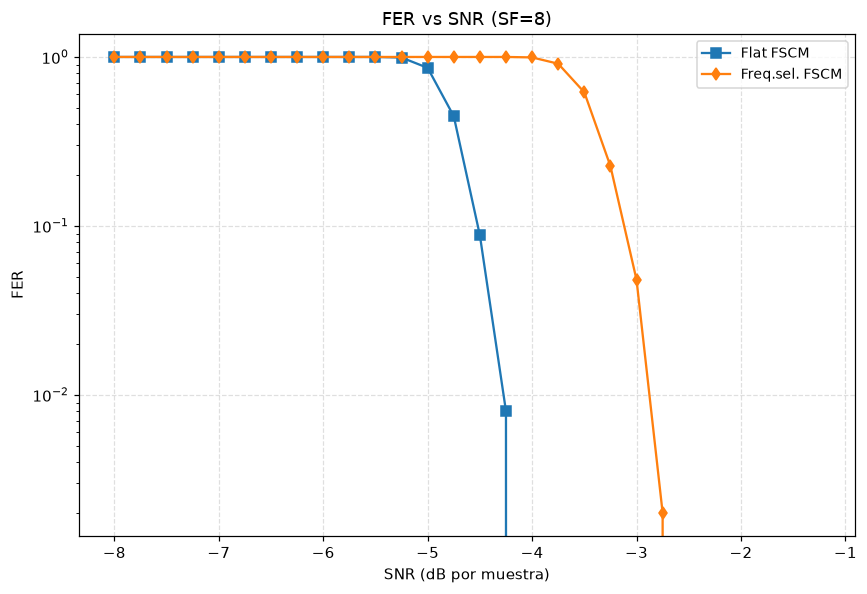

In [18]:
def getFER(N,SF,noise,threshold,sel=False):
    errors = 0
    p = makePreamble(SF,0.0)
    for i in range(N):
        if sel:
            c = Sampling(makePreamble(SF,0.0))
            c.freqSelective()
            c.samples = addNoise(c.samples,noise)
        else:
            c = Sampling(makePreamble(SF,noise))
        (correct,_) = c.identifyPreamble(p,threshold)
        if not correct:
            errors = errors +1
    return errors/N

def graphFER(N,SF,threshold,snrs=np.arange(-8,-1,0.25)):
    rate = lambda N,SF,send,noise,sel=False: getFER(N,SF,noise,threshold,sel)
    graphRateVsSNR("FER",rate,N,SF,None,snrs)

np.random.seed(0)
graphFER(500,8,0.5)

## 6b. SER, BER y FER promediando N intentos
Cada función repite el experimento $N$ veces y devuelve el promedio de errores:
- **SER** = símbolos errados / $N$
- **BER** = bits errados / $(N \cdot SF)$
- **FER** = preámbulos no detectados / $N$

In [ ]:
##parametros: cambiar a gusto
N = 1000          ##cantidad de intentos que se promedian
SF = 8
snr = -12         ##dB por muestra
threshold = 0.5   ##umbral de deteccion del preambulo (para el FER)
noise = snrToSigma(snr,SF)

np.random.seed(0)
SER = getSER(N,SF,None,noise)        ##None = simbolo aleatorio en cada intento
BER = getBER(N,SF,None,noise)
FER = getFER(N,SF,noise,threshold)

print("SF =",SF,"| SNR =",snr,"dB | N =",N)
print("SER =",SER)
print("BER =",BER)
print("FER =",FER)

SF = 8 | SNR = -12 dB | N = 1000
SER = 0.023
BER = 0.01175
FER = 1.0


### Tabla para varias SNR
Lo mismo, pero recorriendo una lista de SNR (canal plano).

In [ ]:
N = 500
SF = 8
threshold = 0.5
snrs = [-16,-14,-12,-10,-8,-6,-4]

np.random.seed(0)
print("%-10s %-10s %-10s %-10s"%("SNR (dB)","SER","BER","FER"))
for i in range(len(snrs)):
    noise = snrToSigma(snrs[i],SF)
    SER = getSER(N,SF,None,noise)
    BER = getBER(N,SF,None,noise)
    FER = getFER(N,SF,noise,threshold)
    print("%-10d %-10.4f %-10.4f %-10.4f"%(snrs[i],SER,BER,FER))

SNR (dB)   SER        BER        FER       
-16        0.4060     0.2028     1.0000    
-14        0.1400     0.0628     1.0000    
-12        0.0160     0.0075     1.0000    
-10        0.0000     0.0000     1.0000    
-8         0.0000     0.0000     1.0000    
-6         0.0000     0.0000     1.0000    
-4         0.0000     0.0000     0.0000    


## 7. Conclusiones de la simulación
- **Modulación/demodulación:** sin ruido el dechirp + FFT da un único pico en el símbolo enviado; con ruido el pico sigue sobresaliendo por la ganancia de procesamiento $2^{SF}$.
- **BER y SER:** bajan con el SNR y el canal selectivo corre las curvas hacia la derecha. Con SNR muy bajo la BER tiende a 0.5 y la SER a casi 1.
- **Detección por fases:** la correlación encuentra la posición, la normalización la vuelve independiente de la escala y el umbral decide. Con silencio y ruido el detector encuentra el inicio exacto de la trama.
- **Fake:** con umbral por encima de ≈ 0.88 se rechaza la secuencia de 8 upchirps.
- **FER:** con umbral fijo la transición es abrupta (poco más de 1 dB) y el canal selectivo la corre hacia la derecha.

# Parte 2 — SDR

## 2.0 Cómo funciona la prueba con el Pluto
- **TX y RX en el mismo equipo.**
- **Silencio:** la trama se manda con ceros antes y después (`before`, `after`), así en la captura se ve dónde está la trama y dónde no hay nada.
- **Buffer cíclico de TX:** el Pluto repite silencio + trama sin parar hasta `tx_destroy_buffer`.
- **Buffer de RX = 2 veces el período:** el RX arranca a grabar en cualquier momento; grabando el doble siempre entra al menos una trama completa. Por eso el inicio detectado no es `before`: depende de cuándo arrancó la captura.
- **Bug del Pluto:** solo transmitía ¼ del buffer, así que se manda la señal repetida 4 veces.
- **`tx_gain` hace de variable de SNR.** La amplitud recibida depende de las ganancias, por eso se detecta con $\rho$.
- **VPN:** la conexión se caía a veces a mitad de la medición; por eso pocas capturas por punto (resolución 1/N).

## 2.1 Parámetros y configuración del Pluto

In [7]:
import adi
##Parametros del chirp
SF = 8
PL = [12,32,21,5,1]
before = 2000        ##silencio antes de la trama (muestras)
after = 2000         ##silencio despues de la trama
threshold = 0.3
##Parametros del pluto
ip = "ip:192.168.1.31"
frec = int(800e6)
bw = int(2.5e6)
tx_gain = 0
rx_gain = 20
SCALE = 2**10 * np.sqrt(2**SF)   ##sqrt(2^SF) deshace la normalizacion del chirp, 2^10 lo lleva al rango del DAC

##trama con silencio = lo que se transmite en loop
preamble = makePreamble(SF,0.0)
trama = sendPayload(SF,PL,0.0)
tramaTx = addSilence(trama,before,after)
buffer_size = 2*len(tramaTx)

sdr = adi.Pluto(ip)
##general
sdr.sample_rate = bw
sdr.rx_lo = frec
sdr.tx_lo = frec
##Rx
sdr.gain_control_mode_chan0 = "manual"
sdr.rx_hardwaregain_chan0 = rx_gain
sdr.rx_buffer_size = buffer_size
sdr.rx_rf_bandwidth = bw
##Tx
sdr.tx_hardwaregain_chan0 = tx_gain
sdr.tx_rf_bandwidth = bw
sdr.tx_cyclic_buffer = True

##rho ideal sin ruido: en la captura entran 2 periodos (2 tramas)
rhoIdeal = np.sum(np.abs(preamble)**2)/(np.linalg.norm(preamble)*np.sqrt(2)*np.linalg.norm(trama))
print("muestras por período:",len(tramaTx),"| buffer rx:",buffer_size,"| ρ ideal ≈ %.2f"%rhoIdeal)

muestras por período: 7904 | buffer rx: 15808 | ρ ideal ≈ 0.58


## 2.2 Detección del preámbulo por fases con el Pluto
Las mismas fases que en la simulación, pero con la captura real. En la Fase 2 se muestran juntas las dos entradas de la correlación: el preámbulo teórico $p[n]$ y la captura $x[n]$ del Pluto.

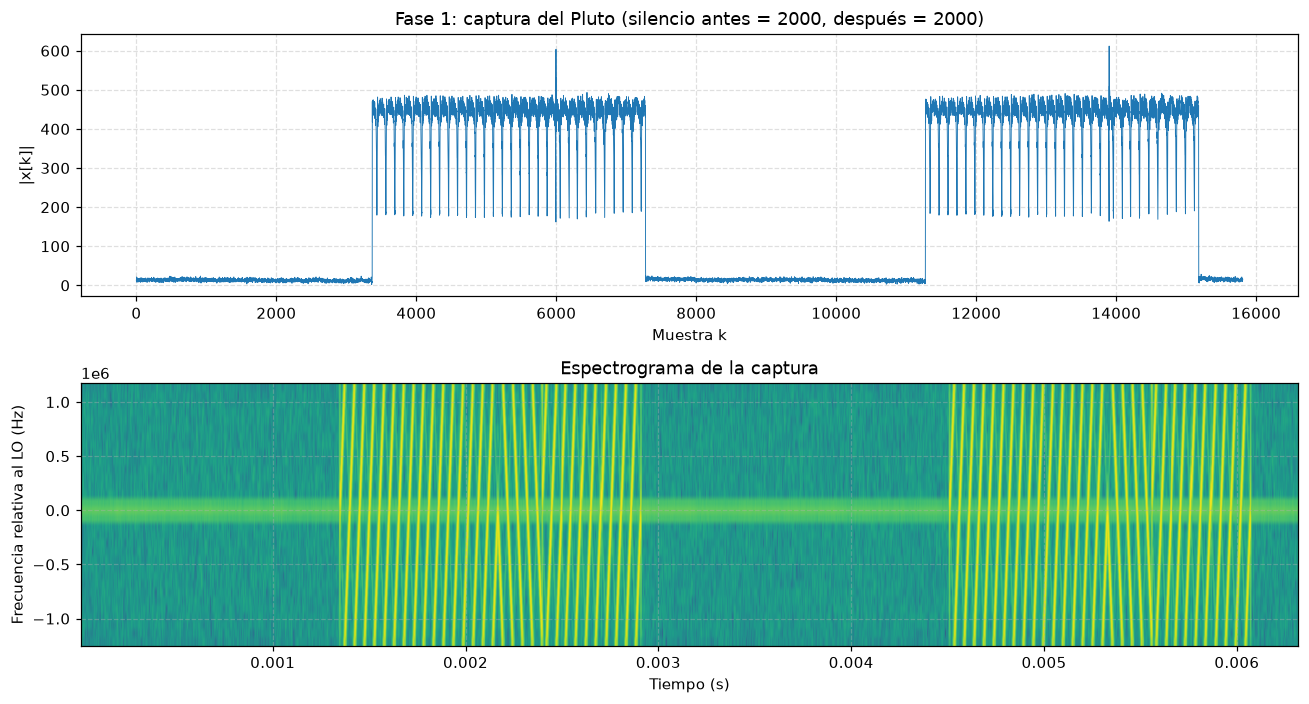

In [20]:
##Fase 1: transmitir y capturar
sdr.tx(np.tile(tramaTx,4)*SCALE)    #bug del pluto solo toma el primer cuarto del buffer
sdr.rx()                             ##la primera captura se descarta
x = sdr.rx()

fig,ax = plt.subplots(2,1,figsize=(12,6.5))
ax[0].plot(np.abs(x),linewidth=0.6)
ax[0].set_xlabel("Muestra k"); ax[0].set_ylabel("|x[k]|")
ax[0].set_title("Fase 1: captura del Pluto (silencio antes = %d, después = %d)"%(before,after))
ax[1].specgram(x,NFFT=32,noverlap=31,Fs=bw,cmap="viridis")
ax[1].set_xlabel("Tiempo (s)"); ax[1].set_ylabel("Frecuencia relativa al LO (Hz)")
ax[1].set_title("Espectrograma de la captura")
plt.tight_layout()
plt.show()

In [ ]:
##Fase 2: correlacion con el preambulo de referencia
c = np.abs(np.correlate(x,preamble,mode="full"))
lag = int(np.argmax(c))

##Fase 3: normalizacion
rho = c/(np.linalg.norm(preamble)*np.linalg.norm(x))

##Fase 4: decision
detecto = rho[lag] > threshold

fig,ax = plt.subplots(4,1,figsize=(12,13))
##las dos entradas de la correlacion: el preambulo teorico y la captura del Pluto
Sampling(preamble).graphFrecuency(title="Preámbulo teórico p[n]: la referencia contra la que se correlaciona",marks=frameMarks(SF,0),ax=ax[0])
ax[1].specgram(x,NFFT=32,noverlap=31,Fs=bw,cmap="viridis")
ax[1].set_xlabel("Tiempo (s)"); ax[1].set_ylabel("Frecuencia (Hz)"); ax[1].set_title("Captura x[n] del Pluto (la señal que se correlaciona)")
##los resultados
ax[2].plot(c,linewidth=0.8)
ax[2].plot(lag,c[lag],"rv",markersize=9,label="máximo en el índice %d"%lag)
ax[2].set_ylabel("|c|"); ax[2].set_title("Fase 2: correlación cruzada |Σ x[n+ℓ] p*[n]| (depende de la amplitud recibida)")
ax[2].legend(loc="upper right")
ax[3].plot(rho,linewidth=0.8)
ax[3].axhline(threshold,color="tab:red",linestyle="--",label="umbral = %.2f"%threshold)
ax[3].axhline(rhoIdeal,color="tab:green",linestyle=":",label="ρ ideal ≈ %.2f"%rhoIdeal)
ax[3].plot(lag,rho[lag],"v",markersize=10,color="tab:green" if detecto else "tab:red",label="máximo ρ = %.2f"%rho[lag])
ax[3].set_xlabel("Índice de la correlación"); ax[3].set_ylabel("ρ"); ax[3].set_ylim(0,1)
ax[3].set_title("Fases 3 y 4: coeficiente de correlación |ρ$_ℓ$| -> %s"%("PREÁMBULO DETECTADO" if detecto else "NO HAY PREÁMBULO"),color="tab:green" if detecto else "tab:red")
ax[3].legend(loc="upper right")
ax[3].sharex(ax[2])
plt.tight_layout()
plt.show()
print("máximo ρ = %.3f, umbral = %.2f -> detecta: %s"%(rho[lag],threshold,detecto))

el preámbulo empieza en la muestra 11274 de la captura


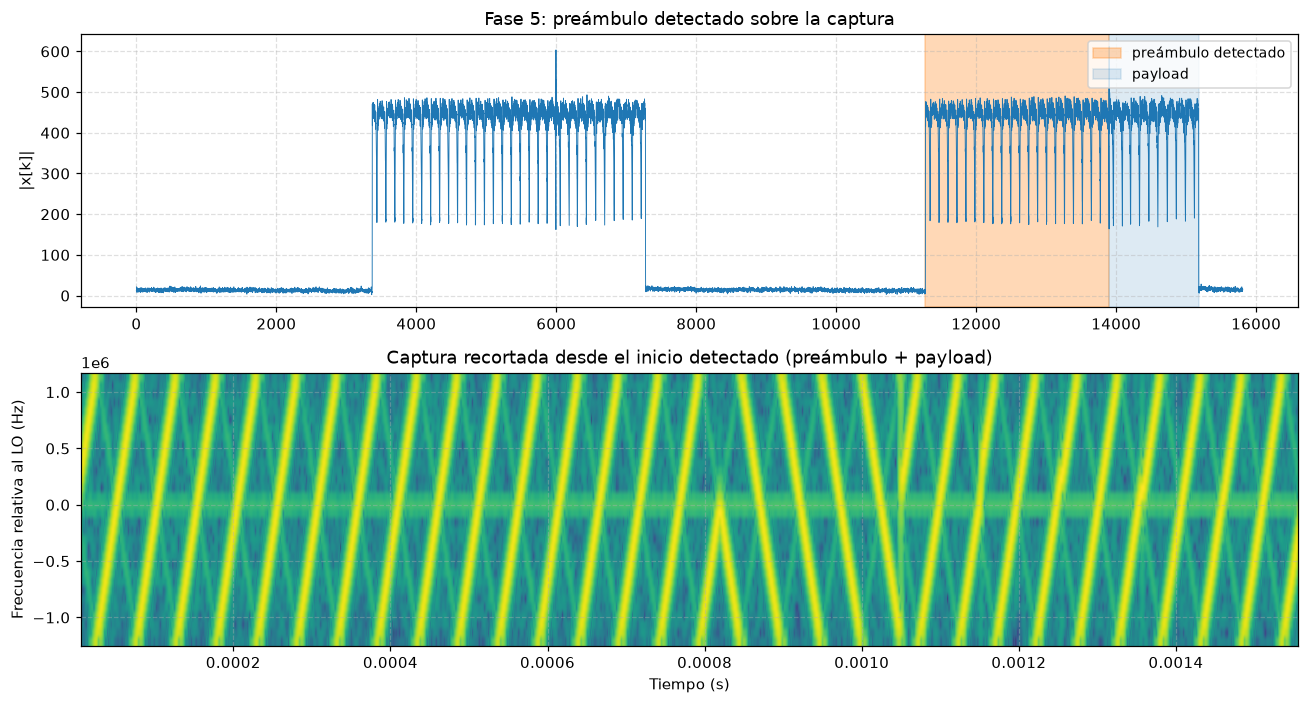

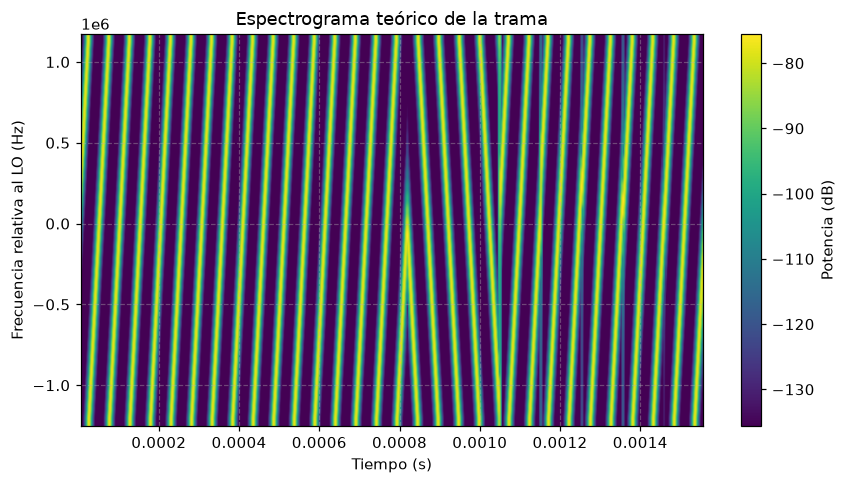

In [22]:
##Fase 5: ubicacion del inicio
inicio = lag - len(preamble) + 1
print("el preámbulo empieza en la muestra",inicio,"de la captura")

fig,ax = plt.subplots(2,1,figsize=(12,6.5))
ax[0].plot(np.abs(x),linewidth=0.6)
ax[0].axvspan(inicio,inicio+len(preamble),color="tab:orange",alpha=0.3,label="preámbulo detectado")
ax[0].axvspan(inicio+len(preamble),inicio+len(trama),color="tab:blue",alpha=0.15,label="payload")
ax[0].set_ylabel("|x[k]|"); ax[0].set_title("Fase 5: preámbulo detectado sobre la captura"); ax[0].legend(loc="upper right")
ax[1].specgram(x[inicio:inicio+len(trama)],NFFT=32,noverlap=31,Fs=bw,cmap="viridis")
ax[1].set_xlabel("Tiempo (s)"); ax[1].set_ylabel("Frecuencia relativa al LO (Hz)")
ax[1].set_title("Captura recortada desde el inicio detectado (preámbulo + payload)")
plt.tight_layout()
plt.show()
graphSpectrogram(trama,bw,"Espectrograma teórico de la trama")
sdr.tx_destroy_buffer()

## 2.3 FER, SER y BER vs `tx_gain`: canal plano y selectivo
Para cada ganancia se transmite la trama (plana y pasada por el canal selectivo por software) y en cada captura:
1. Se busca el preámbulo. Si no está, la trama cuenta para el **FER** y se pierden todos los símbolos y bits del payload.
2. Si está, se corta el payload desde el inicio detectado, se estima cada símbolo (dechirp + FFT) y se cuentan los símbolos (**SER**) y bits (**BER**) errados.

Tarda unos minutos y guarda los resultados en `data/pluto_captures/` con la fecha y la ip en el nombre.

In [5]:
N = 100                              ##capturas por punto
tx_list = np.arange(-85,0,5)      ##mas negativo = menos potencia = peor SNR
sdr.rx_hardwaregain_chan0 = 40

##trama plana y trama por el canal selectivo (con el mismo silencio)
tramaSel = Sampling(tramaTx.copy())
tramaSel.freqSelective()
tramas = [tramaTx, tramaSel.samples]
nombres = ["Flat","Freq.sel."]

nSym = len(PL)
nBits = nSym*SF
periodo = len(tramaTx)

##resultados[canal][ganancia], canal 0 = flat, 1 = selectivo
FER = np.zeros((2,len(tx_list)))
SER = np.zeros((2,len(tx_list)))
BER = np.zeros((2,len(tx_list)))

for idx in range(len(tx_list)):
    sdr.tx_hardwaregain_chan0 = int(tx_list[idx])
    for canal in range(2):
        sdr.tx(np.tile(tramas[canal],4)*SCALE)
        tramasErradas = 0
        simbolosErrados = 0
        bitsErrados = 0
        for i in range(N):
            sdr.rx()
            x = sdr.rx()
            (detecto,lag) = Sampling(x).identifyPreamble(preamble,threshold)
            if not detecto:
                ##sin preambulo no se sabe donde esta el payload: se pierde todo
                tramasErradas += 1
                simbolosErrados += nSym
                bitsErrados += nBits
            else:
                inicio = lag - len(preamble) + 1
                ##si el payload queda cortado al final de la captura se usa la copia anterior (el tx es ciclico)
                if inicio + len(trama) > len(x):
                    inicio = inicio - periodo
                payload = x[inicio+len(preamble) : inicio+len(trama)]
                for k in range(nSym):
                    ventana = payload[k*2**SF : (k+1)*2**SF]
                    est = Sampling(ventana).estimateSymbol()
                    if est != PL[k]:
                        simbolosErrados += 1
                    bitsErrados += bitErrors(PL[k],est,SF)
        FER[canal,idx] = tramasErradas/N
        SER[canal,idx] = simbolosErrados/(N*nSym)
        BER[canal,idx] = bitsErrados/(N*nBits)
        print("tx_gain =",tx_list[idx],nombres[canal],"FER =",FER[canal,idx],"SER =",SER[canal,idx],"BER =",BER[canal,idx])
        sdr.tx_destroy_buffer()

##---------------- Guardar la medicion ----------------
##se guarda en la carpeta data/pluto_captures con la fecha y la ip del pluto en el nombre
##para NO guardar: comentar las lineas de abajo (seleccionarlas y Ctrl+/)
import os, datetime
os.makedirs("../data/pluto_captures", exist_ok=True)
fecha = datetime.datetime.now().strftime("%Y-%m-%d_%H-%M")
archivo = "../data/pluto_captures/pluto_sweep_%s_%s.npz"%(fecha, ip.replace("ip:",""))
np.savez(archivo,tx_list=tx_list,FER=FER,SER=SER,BER=BER,N=N)
print("guardado en",archivo)

tx_gain = -85 Flat FER = 1.0 SER = 1.0 BER = 1.0
tx_gain = -85 Freq.sel. FER = 1.0 SER = 1.0 BER = 1.0
tx_gain = -80 Flat FER = 1.0 SER = 1.0 BER = 1.0
tx_gain = -80 Freq.sel. FER = 1.0 SER = 1.0 BER = 1.0
tx_gain = -75 Flat FER = 1.0 SER = 1.0 BER = 1.0
tx_gain = -75 Freq.sel. FER = 1.0 SER = 1.0 BER = 1.0
tx_gain = -70 Flat FER = 0.04 SER = 0.04 BER = 0.04
tx_gain = -70 Freq.sel. FER = 0.98 SER = 0.98 BER = 0.98
tx_gain = -65 Flat FER = 0.04 SER = 0.04 BER = 0.04
tx_gain = -65 Freq.sel. FER = 0.02 SER = 0.02 BER = 0.02
tx_gain = -60 Flat FER = 0.02 SER = 0.02 BER = 0.02
tx_gain = -60 Freq.sel. FER = 0.02 SER = 0.02 BER = 0.02
tx_gain = -55 Flat FER = 0.01 SER = 0.01 BER = 0.01
tx_gain = -55 Freq.sel. FER = 0.02 SER = 0.02 BER = 0.02
tx_gain = -50 Flat FER = 0.02 SER = 0.02 BER = 0.02
tx_gain = -50 Freq.sel. FER = 0.02 SER = 0.02 BER = 0.02
tx_gain = -45 Flat FER = 0.01 SER = 0.01 BER = 0.01
tx_gain = -45 Freq.sel. FER = 0.01 SER = 0.01 BER = 0.01
tx_gain = -40 Flat FER = 0.01 SER = 0

In [22]:
##grafica una metrica del pluto: canal plano contra selectivo
def graphPluto(name,valores):
    plt.figure(figsize=(9,5))
    plt.semilogy(tx_list,valores[0],marker="s",label="Flat")
    plt.semilogy(tx_list,valores[1],marker="d",label="Freq.sel.")
    plt.xlabel("tx_gain (dB)")
    plt.ylabel(name)
    plt.title("%s vs tx_gain, Pluto (N=%d capturas por punto)"%(name,N))
    plt.legend()
    plt.tight_layout()
    plt.show()

##si ya se midio, descomentar para cargarlo sin repetir:
datos = np.load("../data/pluto_captures/capturagodSweep.npz"); tx_list = datos["tx_list"]; FER = datos["FER"]; SER = datos["SER"]; BER = datos["BER"]; N = int(datos["N"])

### FER (preámbulo no detectado)

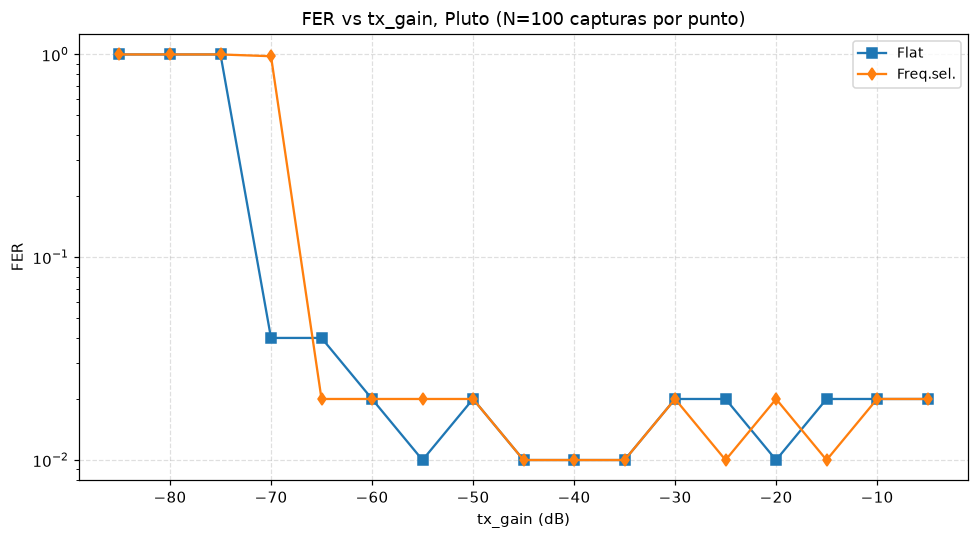

In [9]:
graphPluto("FER",FER)

### SER

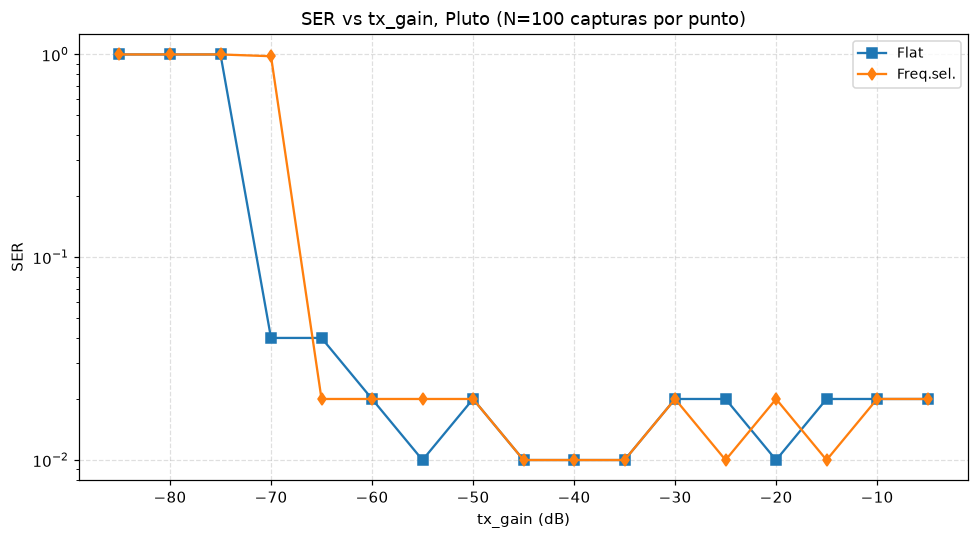

In [10]:
graphPluto("SER",SER)

### BER

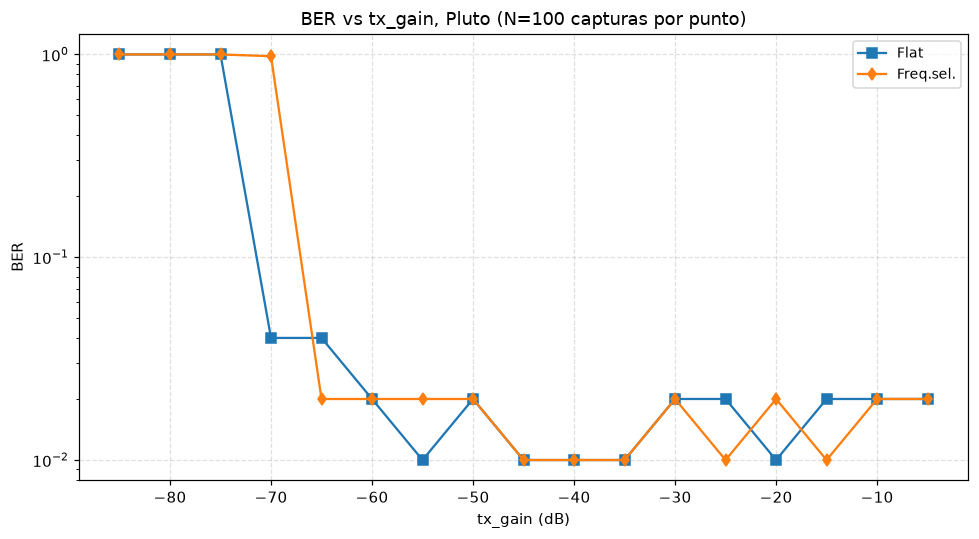

In [11]:
graphPluto("BER",BER)

## 2.4 Liberar el Pluto
Si una celda se corta por un error el Pluto puede quedar transmitiendo. Esta celda lo libera.

In [28]:
sdr.tx_destroy_buffer()
sdr.rx_destroy_buffer()
#del sdr

## 2.5 Qué mirar en la prueba con el Pluto
- **Fase 1:** el silencio se ve como piso de ruido y la trama como un bloque; en el espectrograma aparecen las rampas del preámbulo y del payload.
- **Fase 2:** el valor de $|c|$ depende de las ganancias, por eso no sirve un umbral fijo sobre $|c|$.
- **Fases 3 y 4:** $\rho$ no depende de la escala; el máximo tiene que quedar cerca del $\rho$ ideal y por encima del umbral.
- **Fase 5:** el espectrograma recortado desde el inicio detectado tiene que coincidir con el teórico.
- **FER, SER y BER vs `tx_gain`:** al bajar la potencia pasan de 0 a 1; el canal selectivo necesita más ganancia para el mismo error. Si la SER queda casi igual al FER, casi todo el error viene de no encontrar la trama y no de decodificar mal el payload.

# Parte 3 — OPCIONAL
Complementario a la detección del preámbulo: decodificación del payload y pruebas extra.

## 3.1 Payload
Trama completa = preámbulo + payload. La captura arranca en cualquier punto (se simula con `np.roll`), se detecta el preámbulo, se rota la señal para que quede al inicio y se decodifica cada ventana de $2^{SF}$ muestras con el mismo receptor (dechirp + FFT).

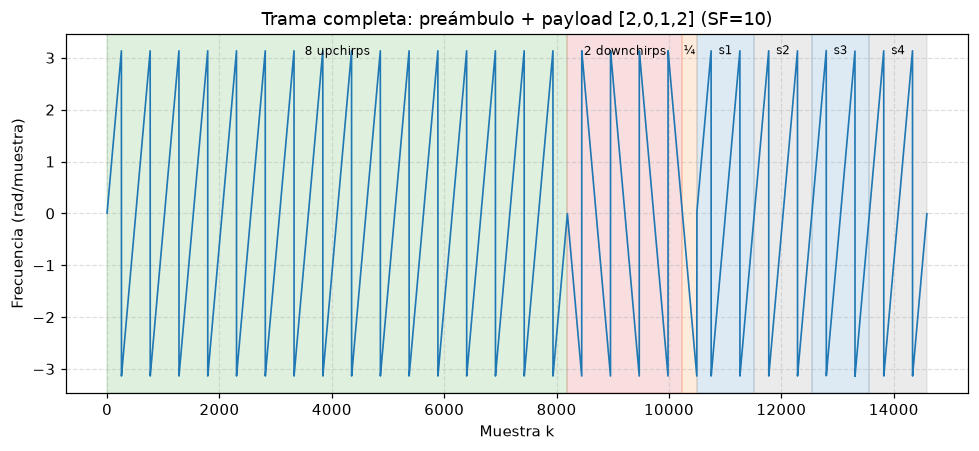

In [29]:
SF = 10
p = Sampling(sendPayload(SF,[2,0,1,2],0.0))
p.graphFrecuency(title="Trama completa: preámbulo + payload [2,0,1,2] (SF=10)",marks=frameMarks(SF,4))

el preámbulo termina en 3623


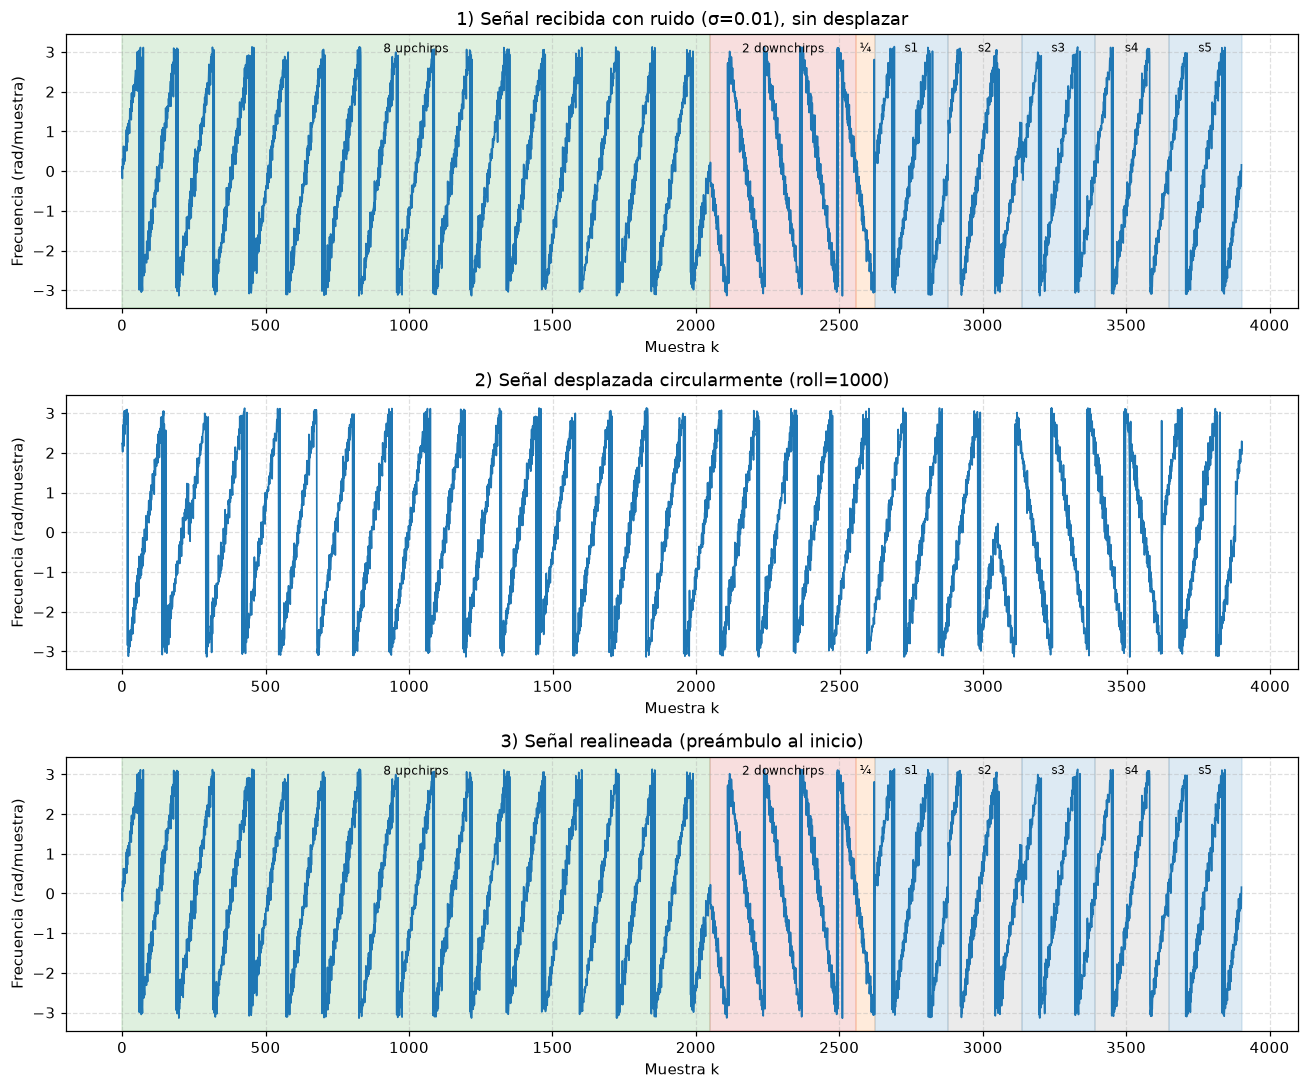

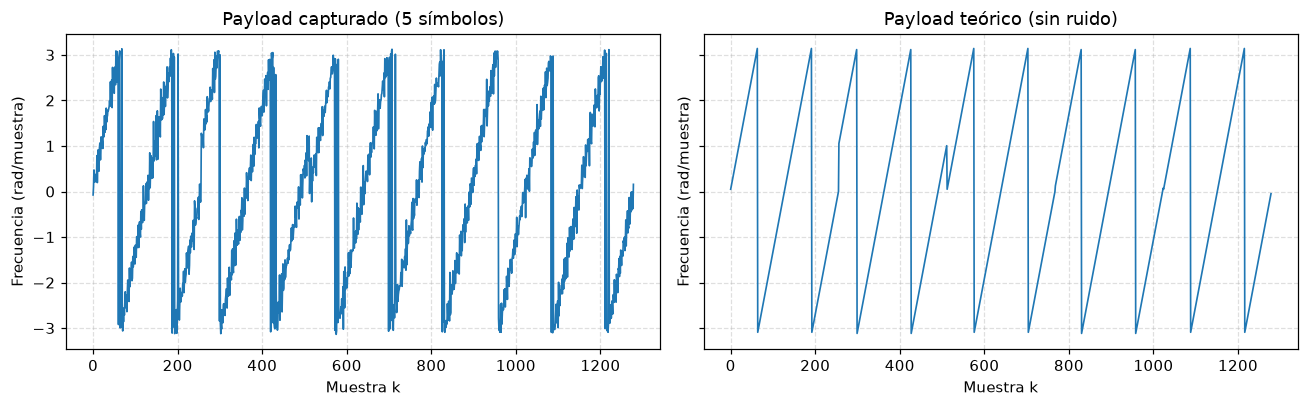

símbolo  enviado    estimado   ok    
1        1          1          sí    
2        42         42         sí    
3        1          1          sí    
4        4          4          sí    
5        1          1          sí    


In [30]:
np.random.seed(3)
SF = 8
roll = 1000
noise = 0.01
pl = [1,42,1,4,1]
preamble = makePreamble(SF,0.0)
preamble = Sampling(preamble)
seq = sendPayload(SF,pl,noise)
seq = Sampling(seq)
nSym = len(pl)

fig,ax = plt.subplots(3,1,figsize=(12,10),sharey=True)
seq.graphFrecuency(title="1) Señal recibida con ruido (σ=0.01), sin desplazar",marks=frameMarks(SF,nSym),ax=ax[0])
seq.samples = np.roll(seq.samples,roll%len(seq.samples))
(correct,lag) = seq.identifyPreamble(preamble.samples,0.0)
print("el preámbulo termina en",lag)
seq.graphFrecuency(title="2) Señal desplazada circularmente (roll=%d)"%roll,ax=ax[1])
##Correccion de preambulo simplemente rotar en el sentido contrario funcion fix
seq.samples = np.roll(seq.samples,-1-lag+len(preamble.samples))
seq.graphFrecuency(title="3) Señal realineada (preámbulo al inicio)",marks=frameMarks(SF,nSym),ax=ax[2])
plt.tight_layout()
plt.show()

##Ahora podemos deshacernos del preambulo no aporta informacion util necesitamos el payload
seq.samples = seq.samples[len(preamble.samples):]
nSymbols = int(len(seq.samples)/(2**SF))

tpl = Sampling(Chirp(SF,pl,True).f)
fig,ax = plt.subplots(1,2,figsize=(12,3.8),sharey=True)
seq.graphFrecuency(title="Payload capturado (%d símbolos)"%nSymbols,ax=ax[0])
tpl.graphFrecuency(title="Payload teórico (sin ruido)",ax=ax[1])
plt.tight_layout()
plt.show()

##finalmente decodificamos cada simbolo con un for
start = 0
end = 2**SF
symbols = [0]*nSymbols
for i in range(nSymbols):
    window = Sampling(seq.samples[start:end])
    symbols[i] = window.estimateSymbol()
    start += 2**SF
    end += 2**SF

print("%-8s %-10s %-10s %-6s"%("símbolo","enviado","estimado","ok"))
for i in range(nSymbols):
    print("%-8d %-10d %-10d %-6s"%(i+1,pl[i],symbols[i],"sí" if pl[i]==symbols[i] else "NO"))

### Versión compacta
`decodeSymbols` hace todo lo anterior en una llamada.

In [31]:
SF = 8
roll = 1000
pl = [1,42,1,4,1]
preamble = makePreamble(SF,0.0)
seq = Sampling(sendPayload(SF,pl,0.0))
seq.samples = np.roll(seq.samples,roll%len(seq.samples))
epl = seq.decodeSymbols(preamble,0.8)
print(epl)
print(pl==epl)

[1, 42, 1, 4, 1]
True


### FER con payload
A diferencia del FER (solo preámbulo), acá también es error de trama un payload decodificado distinto. `getFERpayload` devuelve `(FER con payload, FER de preámbulo)`.

(0.299, 0.299)


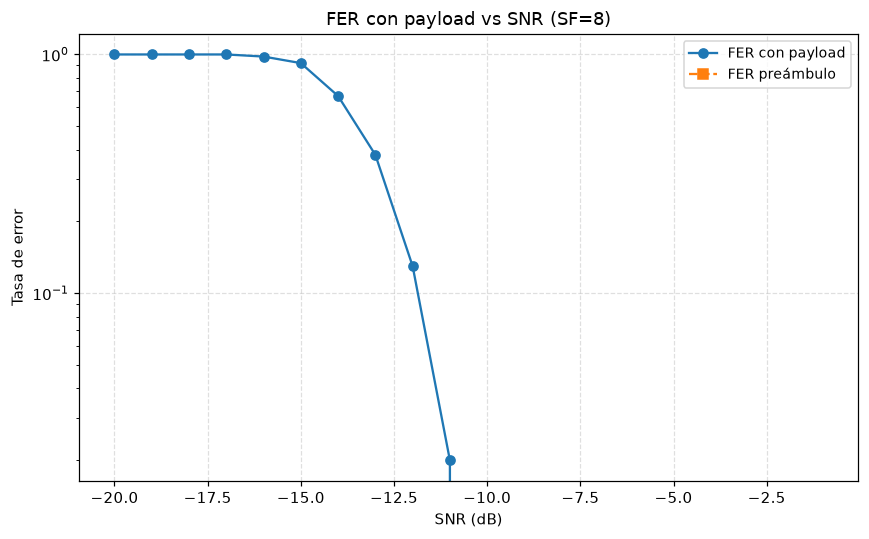

In [32]:
def getFERpayload(N,SF,symbols,noise,threshold):
    errors = 0
    preambleErrors = 0
    p = makePreamble(SF,0.0)
    for i in range(N):
        c = Sampling(sendPayload(SF,symbols,noise))
        correctPayload = c.isCorrectPayload(symbols,p,threshold)
        if(math.isnan(correctPayload)):
            preambleErrors +=1
            errors+=1
        elif not correctPayload:
            errors +=1
    return errors/N,preambleErrors/N

def graphFERpayload(N,SF,symbols,threshold,snrs=np.arange(-20,0,1)):
    ferPayload = np.zeros(len(snrs))
    ferPreambulo = np.zeros(len(snrs))
    for indx in range(len(snrs)):
        (ferPayload[indx],ferPreambulo[indx]) = getFERpayload(N,SF,symbols,snrToSigma(snrs[indx],SF),threshold)
    plt.figure(figsize=(8,5))
    plt.semilogy(snrs,ferPayload,marker="o",label="FER con payload")
    plt.semilogy(snrs,ferPreambulo,marker="s",linestyle="--",label="FER preámbulo")
    plt.xlabel("SNR (dB)")
    plt.ylabel("Tasa de error")
    plt.title("FER con payload vs SNR (SF=%d)"%SF)
    plt.legend()
    plt.tight_layout()
    plt.show()

np.random.seed(0)
print(getFERpayload(2000,8,[1,2,3,2,0,1],0.07,0.42))
##threshold 0.0: siempre detecta, el FER con payload mide solo realineo y decodificacion
graphFERpayload(300,8,[0]*8,0.0)

## 3.2 LS contra LMMSE
Estimador LMMSE sobre la salida del dechirp (informe de la Prof. Corral Briones). *Observación: con SNR = −1 dB en pruebas repetidas el LMMSE acierta bastante menos que el LS; queda como pendiente revisarlo.* La salida del dechirp se toma como estimación LS y se filtra con un Wiener con perfil de potencia exponencial de L taps: $H_{LMMSE}=R_{HH}(R_{HH}+\sigma_n^2I)^{-1}H_{LS}$.

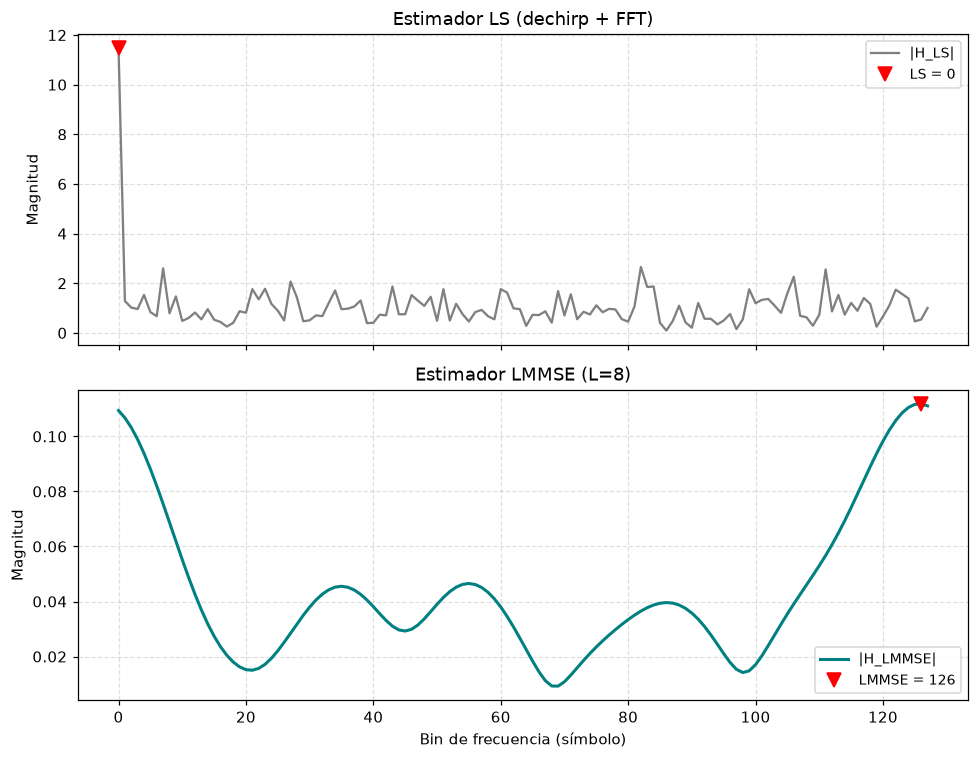

LS: 0 | LMMSE: 126


In [33]:
##noise = sigma por componente (el mismo que se pasa a addNoise)
def estimateSymbolLMMSE(samples, noise, L=8, graph=False):
    N = len(samples)
    sigma_n2 = 2*noise**2*N                      ##potencia de ruido por bin
    H_LS = Sampling(samples).chirpDown()*np.sqrt(N)
    perfil = np.exp(-np.arange(L)/(L/2))
    perfil /= np.sum(perfil)
    R_hh_tiempo = np.zeros((N,N))
    R_hh_tiempo[:L,:L] = np.diag(perfil)
    k, n = np.indices((N,N))
    F = np.exp(-1j*2*np.pi*k*n/N)/np.sqrt(N)
    R_HH = F @ R_hh_tiempo @ F.conj().T
    H_LMMSE = R_HH @ np.linalg.inv(R_HH + sigma_n2*np.eye(N)) @ H_LS
    pico_ls = int(np.argmax(np.abs(H_LS)))
    pico_lmmse = int(np.argmax(np.abs(H_LMMSE)))
    if graph:
        fig, ax = plt.subplots(2,1,figsize=(9,7),sharex=True)
        ax[0].plot(np.abs(H_LS),color="gray",label="|H_LS|")
        ax[0].plot(pico_ls,np.abs(H_LS)[pico_ls],"rv",markersize=9,label="LS = %d"%pico_ls)
        ax[0].set_ylabel("Magnitud"); ax[0].set_title("Estimador LS (dechirp + FFT)"); ax[0].legend()
        ax[1].plot(np.abs(H_LMMSE),color="teal",linewidth=2,label="|H_LMMSE|")
        ax[1].plot(pico_lmmse,np.abs(H_LMMSE)[pico_lmmse],"rv",markersize=9,label="LMMSE = %d"%pico_lmmse)
        ax[1].set_xlabel("Bin de frecuencia (símbolo)"); ax[1].set_ylabel("Magnitud")
        ax[1].set_title("Estimador LMMSE (L=%d)"%L); ax[1].legend()
        plt.tight_layout(); plt.show()
    return pico_lmmse

np.random.seed(0)
SF = 7
noise = snrToSigma(-1,SF)
c = Chirp(SF,[0],True)
c.addNoise(noise)
print("LS:",Sampling(c.f).estimateSymbol(),"| LMMSE:",estimateSymbolLMMSE(c.f,noise,L=8,graph=True))

## 3.3 FER con falsas alarmas *(aporte propio)*
En cada iteración se prueban dos señales: el preámbulo real con ruido (si no se detecta es error) y una secuencia *fake* (si se detecta es falsa alarma y también es error). Así un umbral bajo no tiene ventaja. Devuelve `(FER, DET, FA)`.

In [34]:
def getFERinfo(N,SF,noise,fake:list[int],threshold=0.8):
    errors = 0
    detections = 0
    falseAlarm = 0
    ###Real preamble
    p = makePreamble(SF,0.0)
    for _ in range(N):
        c = Sampling(makePreamble(SF,noise))
        (correct,_) = c.identifyPreamble(p,threshold)
        if not correct:
            errors = errors +1
        else:
            detections +=1
        fakep = Chirp(SF,fake,True)
        fakep.addNoise(noise)
        fakep = Sampling(fakep.f)
        (correct,_) = fakep.identifyPreamble(p,threshold)
        if correct:
            errors = errors +1
            detections +=1
            falseAlarm +=1
    return errors/(N*2),detections/(N*2),falseAlarm/(N)

np.random.seed(0)
print(getFERinfo(1000,8,0.033,[1]*8))

(0.1795, 0.3205, 0.0)


## 3.4 Barrido de umbral y curva ROC *(aporte propio)*
FER, DET y FA contra el umbral con SNR fijo. El umbral óptimo es el de menor FER; la ROC grafica DET contra FA. *N chico para que termine rápido.*

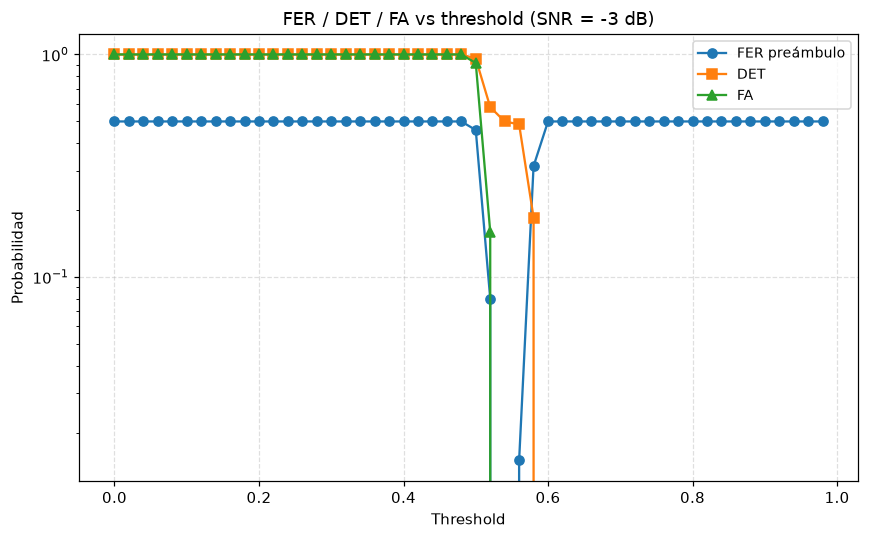

threshold optimo 0.54


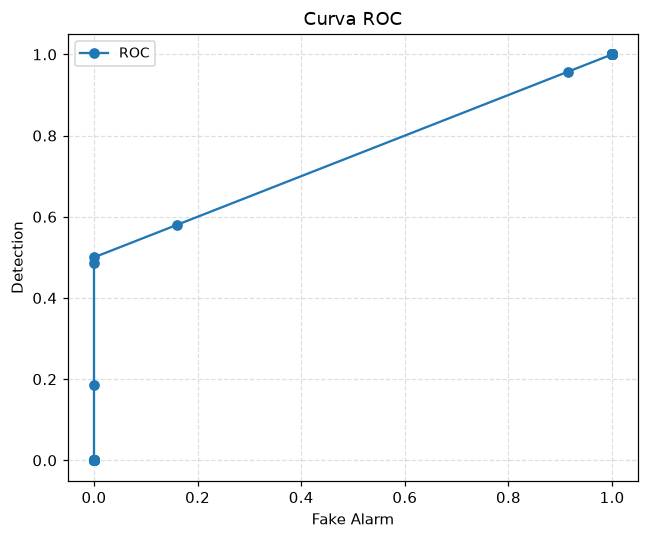

In [35]:
def graphFERthreshold(N,SF,snr,fake:list[int]):
    thresholds = np.arange(0,1,0.02)
    noise = snrToSigma(snr,SF)
    fer = np.zeros(len(thresholds))
    det = np.zeros(len(thresholds))
    fa = np.zeros(len(thresholds))
    for indx in range(len(thresholds)):
        (fer[indx],det[indx],fa[indx]) = getFERinfo(N,SF,noise,fake,thresholds[indx])

    plt.figure(figsize=(8,5))
    plt.semilogy(thresholds,fer,marker="o",label="FER preámbulo")
    plt.semilogy(thresholds,det,marker="s",label="DET")
    plt.semilogy(thresholds,fa,marker="^",label="FA")
    plt.xlabel("Threshold")
    plt.ylabel("Probabilidad")
    plt.title("FER / DET / FA vs threshold (SNR = %d dB)"%snr)
    plt.legend()
    plt.tight_layout()
    plt.show()
    best = np.argmin(fer)
    print("threshold optimo",thresholds[best])

    plt.figure(figsize=(6,5))
    plt.plot(fa,det,marker="o",label="ROC")
    plt.xlabel("Fake Alarm")
    plt.ylabel("Detection")
    plt.title("Curva ROC")
    plt.legend()
    plt.tight_layout()
    plt.show()

np.random.seed(0)
graphFERthreshold(200,8,-3,[0]*8)

## 3.5 Pluto: test real con decodificación del payload
Misma lógica que la v2: trama sin silencio con el buffer del tamaño de una trama, `fixPreamble` rota la captura para que el preámbulo quede al inicio y `decodeSymbols` decodifica el payload.

> Salida guardada: medición del laboratorio.

False


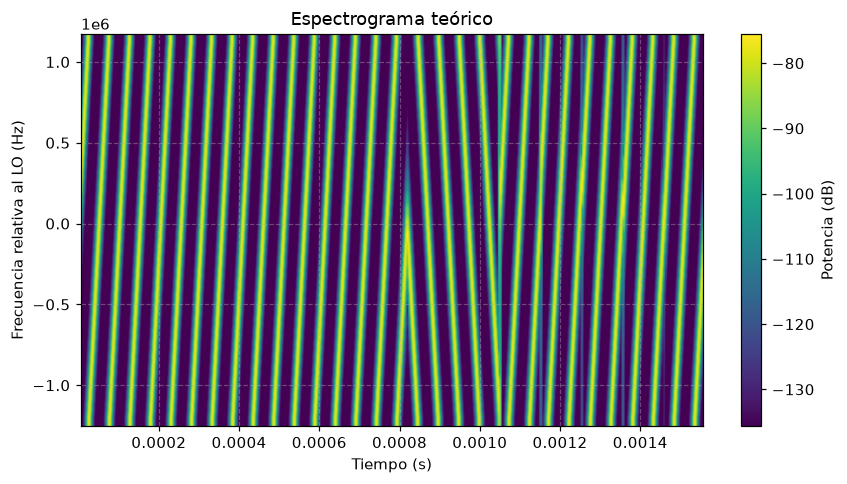

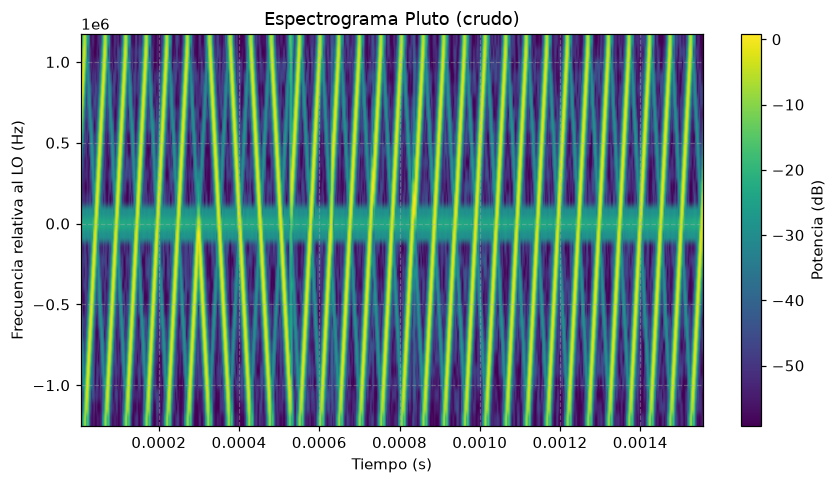

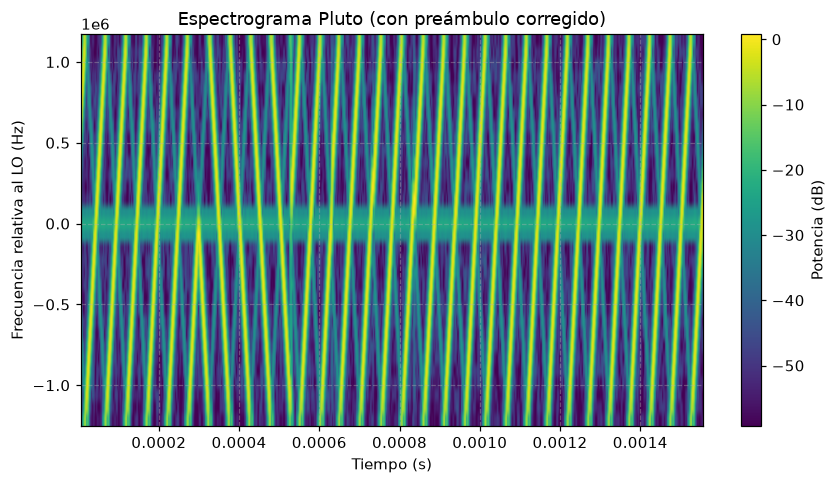

[42, 42, 42, 42, 42]


In [36]:
import adi
##Chirp parameters
SF = 8
PL = [12,32,21,5,1]
threshold = 0.42
##Pluto parameters
sdr = adi.Pluto("ip:192.168.1.31")
frec = int(800e6)
bw = int(2.5e6)
tx_gain = 0
rx_gain = 20
buffer_size = int((len(PL)+10.25)*2**SF)
SCALE = 2**10 * np.sqrt(2**SF)
##general
sdr.sample_rate = bw
sdr.rx_lo = frec
sdr.tx_lo = frec
##Rx
sdr.gain_control_mode_chan0 = "manual"
sdr.rx_hardwaregain_chan0 = rx_gain
sdr.rx_buffer_size = buffer_size
sdr.rx_rf_bandwidth = bw
#Tx
sdr.tx_hardwaregain_chan0 = tx_gain
sdr.tx_buffer_size = buffer_size
sdr.tx_rf_bandwidth = bw
sdr.tx_cyclic_buffer = True

preamble = makePreamble(SF,0.0)
data = sendPayload(SF,PL,0.0)
sdr.tx(np.tile(data,4)*SCALE)   #bug del pluto solo toma el primer cuarto del buffer
sdr.rx()
recovered = sdr.rx()
plutoData = Sampling(recovered)
print(plutoData.fixPreamble(preamble,threshold))
graphSpectrogram(data,bw,"Espectrograma teórico")
graphSpectrogram(recovered,bw,"Espectrograma Pluto (crudo)")
graphSpectrogram(plutoData.samples,bw,"Espectrograma Pluto (con preámbulo corregido)")
sdr.rx_destroy_buffer()
sdr.tx_destroy_buffer()
print(plutoData.decodeSymbols(preamble,threshold,done=True))

## Límites y referencias
**Límites**
- Preámbulo y detección más simples que los de LoRa real (sin sync word ni corrección de CFO).
- El umbral de ρ depende del largo de la captura y del ruido.
- En el Pluto el SNR no se mide: se varía `tx_gain`. Pocas capturas por punto (resolución 1/N) por la VPN.

**Hacia un sistema funcional:** campo LEN después del preámbulo, bits de control y el protocolo LoRaWAN.

**Progreso del TP:** las versiones anteriores están en **[github.com/emanuelpinque-cmd/LoRa-Modulation](https://github.com/emanuelpinque-cmd/LoRa-Modulation)**.

**Referencias**
1. L. Vangelista, "Frequency Shift Chirp Modulation: The LoRa Modulation," *IEEE Signal Processing Letters*, vol. 24, no. 12, pp. 1818–1821, 2017.
2. G. Corral Briones, "Identificación de picos de sincronismo con el estimador LMMSE" (informe de la cátedra).

## Instalación de dependencias

In [37]:
%pip install pyadi-iio matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


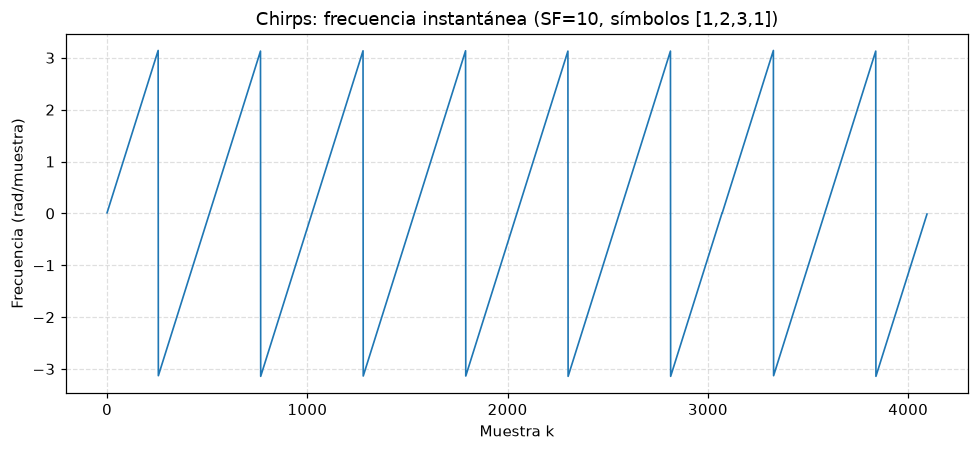

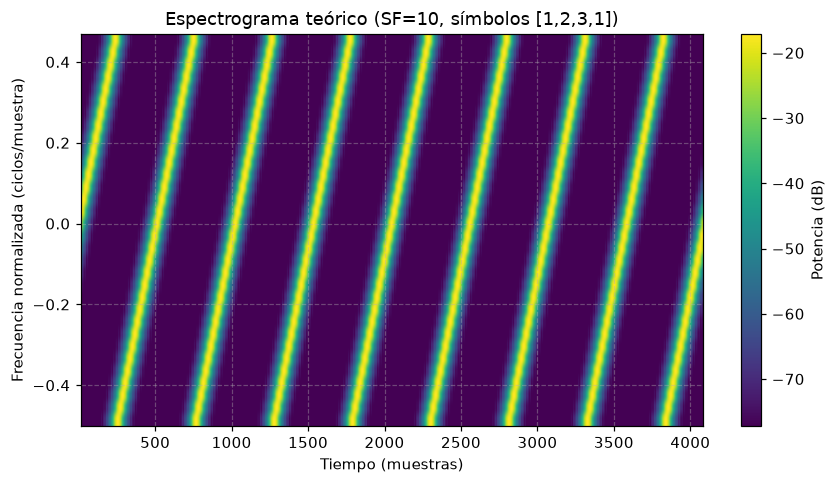

funciones cargadas


In [2]:
##Arranque rapido para el Pluto: despues de reiniciar el kernel, corre solo las celdas
##que definen las funciones que se necesitan (no corre las simulaciones lentas)
##OJO: lee el notebook guardado en disco, guardar (Ctrl+S) antes de usarla
import json

necesarias = ["def symbolChirp",       ##1. funciones base: Chirp, makePreamble, sendPayload, bitErrors
              "class Sampling",         ##1b. receptor: identifyPreamble, estimateSymbol, freqSelective
              "def graphSpectrogram",   ##1e. espectrograma (lo usa la fase 5)
              "def addSilence"]         ##5. silencio y ruido

nb = json.load(open("LoRa_V8.ipynb"))
for celda in nb["cells"]:
    codigo = "".join(celda["source"])
    if celda["cell_type"] == "code" and any(nombre in codigo for nombre in necesarias):
        exec(codigo)
print("funciones cargadas")
